# Gwangyang: the real-time chain on Server A, from a waveform file to a relocated origin

**What was tested (step 10, note `docs/results/10_gwangyang_realtime.md`).** A SeisComP 7.4.0 real-time chain ran on
Server A with all messaging on the loopback interface (localhost only):
waveform file → scautopick with SED's deep-learning picker plugin → scmaster (database) → scautoloc (LOCSAT) →
scevent → scrtdd (real-time double-difference relocation against a reference catalog) → database.
Two Gwangyang earthquakes were replayed through it: 20210827220322 (KMA $\mathit{M}_{\mathrm{L}}$ 2.2, called
event 3 here) and 20260202194119 (KMA $\mathit{M}_{\mathrm{L}}$ 1.6, event 9). Five runs were made (RT1-RT5). The
first one failed at scautoloc and is kept as evidence; the other four worked.

**This notebook replays nothing.** It loads the files the runs left behind (result tables, logs, option dumps,
network records and read-only copies of the databases) and draws five figures:

1. the data flow, with what each program adds;
2. when each piece was created, in the runs fed at real-time pace (latency);
3. where the starting location and the relocated location lie, against the offline reference solutions;
4. an overview of the five runs and the two failures;
5. what the S picks would add, which the chain loses.

It ends with a comprehensive summary (computed table, take-home messages, caveats, how to reproduce).

**Terms used throughout, in plain words**

- *Pick*: the time a program marks as the arrival of a P wave (compressional, first) or an S wave (shear, later)
  at one station. Here the picks come from a deep-learning (DL) model (PhaseNet with its original weights) inside
  scautopick; its P picks are labeled DL3C and its S picks SDL3C. The model also reports a *confidence* between 0
  and 1, which SeisComP stores in the field it normally uses for a signal-to-noise ratio (SNR).
- *Amplitude*: a measured wave size attached to a pick (types snr, mb, MLv, mB). scautoloc uses a P pick only once
  its *mb* amplitude has been measured.
- *Origin*: one computed location and origin time (when and where the earthquake started). One earthquake gets
  several origins, as more picks arrive (*versions*) and after relocation.
- *LOCSAT*: SeisComP's standard locator. scautoloc runs it with the global velocity model iasp91, from P picks only.
- *Event*: SeisComP's container for all origins of one earthquake; scevent creates it and marks one origin as the
  *preferred origin*, the one other programs use.
- *Relocation (scrtdd)*: scrtdd moves an origin by comparing its travel times with those of well-located earlier
  earthquakes nearby (the *reference catalog*), using *double differences*: the difference between two events'
  travel times to the same station, observed minus predicted. Waveform cross-correlation refines these
  differences. The result is a new origin with methodID RTDD (a *relocated origin*).
- *Messaging*: the programs never talk to each other directly. Each sends its results to scmaster in a named
  *group* (PICK, AMPLITUDE, LOCATION, EVENT, RELOCATION), and scmaster forwards them to every program that
  subscribed to that group and stores them in the database.
- *File feed / paced feed*: the waveform file is either read at full speed (*file*, a whole 9-minute file in
  seconds, so creation times show processing time only) or released record by record at the original pace by
  SeisComP's msrtsimul (*paced*), which imitates a live data stream.
- *Latency*: how long after the earthquake's origin time something was created.
- *S1*: step 08's multi-event scrtdd solution of all 11 Gwangyang events; the reference catalog of this test is
  S1 without the two replayed events. *HypoDD dt.cc*: the HypoDD relocation with cross-correlation times
  (reference table). *SEa*: step 08's offline single-event relocation (PhaseNet+ P and S picks).
- *3-D distance*: the straight-line distance between two hypocenters in space.

**Contents**

0. Parameters
1. Loading the files, with checks of the intermediate values
2. Figure 1: the data flow
3. Figure 2: latency in the paced runs
4. Figure 3: positions (start, real-time relocation, offline references)
5. Figure 4: the five runs and the two failures
6. Figure 5: P only (real time) against P + S (offline)
7. Comprehensive summary

## 0. Parameters

Every setting of this notebook is in the next cell: input folders, the runs used by each figure, time windows,
zoom sizes and the histogram bins. Nothing further down changes them. The settings of the SeisComP programs
themselves are not parameters here; they are read from each run's own option dumps (section 2 lists them).

In [1]:
# ============================== PARAMETERS ==============================
# every setting of this notebook; nothing below changes these values (the markdown text quotes them)
import time as _time
T_START = _time.time()                                   # the run time is printed at the very end
PROJECT = "/home/msseo/works/74.SeisComP_rtDD_DLpicker"
RT_ROOT = f"{PROJECT}/runs/gwangyang/realtime"           # the five real-time runs (read only)
SCRIPTS = f"{RT_ROOT}/scripts"                           # rt_analyze.py (positions, times), rt_chain.py (SQL read-back)
COMPARISON = f"{RT_ROOT}/comparison"                     # tables of all runs together (rt_analyze.py)
EVENT_ID_MAP = f"{PROJECT}/data/gwangyang_11ev/reference_tables/event_id_map.csv"   # KMA origin times and magnitudes
FIG_DIR = f"{PROJECT}/notebooks/figures"                 # every figure as 04_*.png (200 dpi) and 04_*.pdf
LIB = f"{PROJECT}/notebooks/lib"                         # nbfont.py (Helvetica) and nb04_helpers.py
DB_COPY_PARENT = f"{PROJECT}/notebooks"                  # a temporary folder for the database copies is made here
                                                         # and removed right after reading

# --- runs and events ---
RUNS = ["RT1_filefeed", "RT2_filefeed", "RT3_paced", "RT4_filefeed_prefer_rtdd", "RT5_paced_creationtime"]
MAIN_RUN = "RT2_filefeed"                 # the main run of note 10: positions (Figure 3) and the offline P / P+S check (Figure 5)
PACED_RUNS = ["RT3_paced", "RT5_paced_creationtime"]   # Figure 2: the runs fed at real-time pace
SCAUTOLOC_FAIL_RUN = "RT1_filefeed"       # Figure 4b: the run where scautoloc rejected every DL pick
RELOC_FAIL_RUN = "RT5_paced_creationtime" # Figure 4c: the run with the failed relocation attempt
REPLAYED = ["20210827220322", "20260202194119"]   # KMA ids of the replayed events, in replay order

# --- Figure 2 (timeline) ---
PICK_WINDOW_S = (-200.0, 400.0)  # picks of one replay: pick time within this window around the KMA origin time
                                 # (the same rule as rt_analyze.py)
TIMELINE_EARLY_S = (-25.0, 85.0) # left part of the time axis (s after the final LOCSAT origin time)
TIMELINE_LATE_S = (195.0, 292.0) # right part, drawn at a compressed scale (late scautoloc updates)

# --- Figures 3 and 5 (positions) ---
OVERVIEW_PAD_KM = 0.3            # Figure 3: margin around the plotted points in the km-scale panels
ZOOM_HALF_WIDTH_M = 115.0        # Figure 3: m-scale panels, half width around the centroid of the 9 reference events (S1)
ZOOM_HALF_DEPTH_M = 115.0        # Figure 3: m-scale depth sections, half height around that centroid's depth
FIG5_ZOOM_FACTOR = 1.35          # Figure 5: half width = this factor x the largest offset from S1 (at least FIG5_MIN_HALF_M)
FIG5_MIN_HALF_M = 6.0

# --- Figure 4 (failures) ---
RESID_RANGE_MS = (-400.0, 1600.0)   # Figure 4c: residual axis (residuals outside are counted, not drawn)
RESID_BIN_MS = 25.0                 # Figure 4c: histogram bin width

DPI = 200

In [2]:
# imports, Helvetica, versions, the canonical scripts, colors and labels
import os
import sys
import re
import json
import glob
import importlib
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from IPython.display import display, Markdown
import obspy
from obspy import UTCDateTime

sys.path.insert(0, "/home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/lib")
assert sys.path[0] == LIB
import nbfont
FONT_FAMILY = nbfont.use_helvetica(verbose=True)
FM = matplotlib.font_manager
print("resolved font family:", FONT_FAMILY)
print("  regular face file:", FM.findfont(FM.FontProperties(family=["sans-serif"])))
BOLD_FILE = FM.findfont(FM.FontProperties(family=["sans-serif"], weight="bold"))
print("  bold face file:   ", BOLD_FILE)
BOLD = "bold" if "Bold" in os.path.basename(BOLD_FILE) else "normal"   # a real bold face only, never a faked one
import nb04_helpers as h4
importlib.reload(h4)
RA = h4.load_script(f"{SCRIPTS}/rt_analyze.py", "rt_analyze")   # canonical enu(), t_sql(), t_log(), load_solution(), load_se()
RC = h4.load_script(f"{SCRIPTS}/rt_chain.py", "rt_chain")       # canonical SQL read-back queries (rt_chain.SQL); nothing is run
plt.rcParams.update({"font.size": 9, "axes.titlesize": 9.5, "axes.labelsize": 9, "legend.fontsize": 8,
                     "xtick.labelsize": 8, "ytick.labelsize": 8, "figure.dpi": 100,
                     "legend.edgecolor": "0.6", "legend.framealpha": 1.0, "legend.facecolor": "white",
                     "axes.spines.top": True, "axes.spines.right": True,
                     "mathtext.cal": "Helvetica:italic"})
os.makedirs(FIG_DIR, exist_ok=True)
pd.set_option("display.width", 230)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 70)

ML = r"$\mathit{M}_{\mathrm{L}}$"
# Okabe-Ito colors; the same meaning in every figure
COL = {"P": "#56B4E9", "S": "#E69F00", "mb": "#009E73", "locsat": "#D55E00", "event": "#CC79A7",
       "rtdd": "#0072B2", "rtdd_early": "#56B4E9", "wait": "#A6CEE3", "s1": "#000000", "hypodd": "#009E73",
       "ps": "#E69F00", "sea": "#CC79A7", "ref": "0.60", "unused": "0.68", "fail": "#000000"}
OK_FC, BAD_FC, NA_FC = "#DCEBF5", "#F8DCCB", "0.93"     # table cells: worked / failed / not applicable
print("versions: numpy", np.__version__, "| pandas", pd.__version__, "| obspy", obspy.__version__,
      "| matplotlib", matplotlib.__version__)
print("canonical scripts:", RA.__file__, "|", RC.__file__)

font family in use: Helvetica (8 faces registered)
resolved font family: Helvetica
  regular face file: /home/msseo/.local/share/fonts/helvetica-family/Helvetica-Regular.otf
  bold face file:    /home/msseo/.local/share/fonts/helvetica-family/Helvetica-Bold.otf
versions: numpy 2.5.4 | pandas 3.0.6 | obspy 1.5.1 | matplotlib 3.11.2
canonical scripts: /home/msseo/works/74.SeisComP_rtDD_DLpicker/runs/gwangyang/realtime/scripts/rt_analyze.py | /home/msseo/works/74.SeisComP_rtDD_DLpicker/runs/gwangyang/realtime/scripts/rt_chain.py


## 1. Loading the files, with checks of the intermediate values

### 1.1 Result tables, comparison tables and reference solutions

Per run (`runs/gwangyang/realtime/<run>/`): `results/*.csv` and `results/summary.json` (made by `rt_analyze.py`),
`options/run_options.json` and `options/scautopick.settings.json` (every option value, with the file and line it
came from), `replays.json`, `run_variant.json`. For all runs together: `comparison/summary_all_runs.json`,
`delays_all_runs.csv`, `positions_vs_reference_all_runs.csv` and `context_S1_vs_other_offline_solutions.csv`.
The reference positions (S1, HypoDD dt.cc, SEa) are read with `rt_analyze.py`'s own loaders, so every position in
this notebook is in the same local east/north/up frame (meters about 35.0000 N 127.7286 E, as in steps 07-09).

In [3]:
# 1.1 load the result tables of the five runs, the comparison tables and the reference solutions
assert list(RA.REPLAY) == REPLAYED, "the replayed events differ from rt_analyze.py"
RID = {k: int(RA.REPLAY[k]) for k in REPLAYED}                     # rtdd ids (event numbers used throughout)
EVMAP = pd.read_csv(EVENT_ID_MAP, dtype={"kma_id": str}).set_index("kma_id")
ML_OF = {k: float(EVMAP.loc[k, "kma_ml"]) for k in REPLAYED}
KMA_OT = {k: UTCDateTime(EVMAP.loc[k, "kma_origin_utc"]) for k in REPLAYED}
assert all(abs(KMA_OT[k] - UTCDateTime(RA.KMA_OT[k])) < 1e-6 for k in REPLAYED)


def evlabel(k):
    return f"Event {RID[k]} ({ML} {ML_OF[k]:.1f})"


def read_csv_or_empty(path, **kw):
    try:
        return pd.read_csv(path, **kw)
    except pd.errors.EmptyDataError:
        return pd.DataFrame()


R = {}
for run in RUNS:
    d = f"{RT_ROOT}/{run}"
    r = dict(dir=d)
    for name in ("delays", "origins", "positions_vs_reference", "scrtdd_relocations", "scrtdd_step1_weighting",
                 "scrtdd_diagnostics_dd_counts", "picks_vs_offline"):
        r[name] = read_csv_or_empty(f"{d}/results/{name}.csv", dtype={"kma_id": str})
    r["summary"] = json.load(open(f"{d}/results/summary.json"))
    r["options"] = json.load(open(f"{d}/options/run_options.json"))
    r["settings"] = json.load(open(f"{d}/options/scautopick.settings.json"))
    r["replays"] = json.load(open(f"{d}/replays.json"))
    r["variant"] = json.load(open(f"{d}/run_variant.json")) if os.path.exists(f"{d}/run_variant.json") else {}
    R[run] = r
COMP = json.load(open(f"{COMPARISON}/summary_all_runs.json"))
DALL = pd.read_csv(f"{COMPARISON}/delays_all_runs.csv", dtype={"kma_id": str})
PALL = pd.read_csv(f"{COMPARISON}/positions_vs_reference_all_runs.csv", dtype={"kma_id": str})
CTX = pd.read_csv(f"{COMPARISON}/context_S1_vs_other_offline_solutions.csv")
OFFCHK = pd.read_csv(f"{RT_ROOT}/{MAIN_RUN}/offline_check/offline_check.csv", dtype={"kma_id": str})
OFFFAIL = pd.read_csv(f"{RT_ROOT}/{RELOC_FAIL_RUN}/offline_check_failed/offline_check.csv", dtype={"kma_id": str})

S1 = RA.load_solution("S1")
HDD = RA.load_solution("HypoDD_dtcc")
SEA = RA.load_se("SEa")
REF_IDS = list(RA.REF_IDS)
C_S1 = S1.loc[REF_IDS, ["E", "N", "U"]].mean()          # centroid of the 9 reference events in S1
C_HDD = HDD.loc[REF_IDS, ["E", "N", "U"]].mean()        # ... and in HypoDD dt.cc
HDD_S1FRAME = HDD[["E", "N", "U"]] - C_HDD + C_S1         # HypoDD moved into S1's frame (centroids matched)
print("reference solutions (rt_analyze.SOLUTIONS / SE_RESULTS):")
for nm in ("S1", "HypoDD_dtcc"):
    print(f"  {nm}: {RA.SOLUTIONS[nm][0]}")
print(f"  SEa: {RA.SE_RESULTS['SEa']}")
print(f"frame shift S1 minus HypoDD dt.cc (centroids of the {len(REF_IDS)} reference events): "
      f"E {C_S1.E - C_HDD.E:+.1f} m, N {C_S1.N - C_HDD.N:+.1f} m, U {C_S1.U - C_HDD.U:+.1f} m")
for k in REPLAYED:
    print(f"{k}: {evlabel(k).replace(ML, 'ML')}, KMA origin {KMA_OT[k]}")
print("runs:", ", ".join(f"{run} ({len(R[run]['replays'])} replays)" for run in RUNS))

reference solutions (rt_analyze.SOLUTIONS / SE_RESULTS):
  S1: /home/msseo/works/74.SeisComP_rtDD_DLpicker/runs/gwangyang/scrtdd/S1/work/reloc-event.csv
  HypoDD_dtcc: /home/msseo/works/74.SeisComP_rtDD_DLpicker/data/gwangyang_11ev/reference_tables/hypodd_dtcc.csv
  SEa: /home/msseo/works/74.SeisComP_rtDD_DLpicker/runs/gwangyang/scrtdd/SEa/single_event_results.csv
frame shift S1 minus HypoDD dt.cc (centroids of the 9 reference events): E -317.1 m, N +33.5 m, U -172.2 m
20210827220322: Event 3 (ML 2.2), KMA origin 2021-08-27T22:03:22.000000Z
20260202194119: Event 9 (ML 1.6), KMA origin 2026-02-02T19:41:19.000000Z
runs: RT1_filefeed (1 replays), RT2_filefeed (2 replays), RT3_paced (2 replays), RT4_filefeed_prefer_rtdd (2 replays), RT5_paced_creationtime (2 replays)


### 1.2 The databases, read from read-only copies

Each run's database (`<run>/db/seiscomp.sqlite`, written by scmaster) is copied into a temporary folder, the copy
is opened read-only, the same six SQL queries `rt_chain.py dump` used are run on it, and the folder is deleted.
The md5 of the original file is taken before and after. The table below compares every row of the copy with the
run's own read-back (`db_dump/sql_*.csv`): same rows, same publicIDs and the same creation times to the
microsecond.

In [4]:
# 1.2 every run's database, read from a read-only copy, against the run's own read-back tables
DB, rows = {}, []
for run in RUNS:
    tabs, info = h4.read_db_copy(f"{RT_ROOT}/{run}/db/seiscomp.sqlite", RC.SQL, DB_COPY_PARENT)
    DB[run] = tabs
    row = {"Run": run, "Files copied": info["files_copied"], "Journal": info["journal_mode"],
           "Original unchanged (md5)": info["original_unchanged"], "Copy removed": info["temporary_copy_removed"]}
    for name in ("picks", "amplitudes", "origins", "arrivals", "events"):
        dump = pd.read_csv(f"{RT_ROOT}/{run}/db_dump/sql_{name}.csv")
        live = tabs[name]
        same = len(dump) == len(live)
        if same and len(live):
            if "publicID" in live:
                a = live.set_index("publicID").sort_index()
                b = dump.set_index("publicID").sort_index()
                same = a.index.equals(b.index)
                for c in ("creationInfo_creationTime", "creationInfo_creationTime_ms"):
                    if same and c in a:
                        same = bool((a[c].astype(str).to_numpy() == b[c].astype(str).to_numpy()).all())
            else:
                key = ["originID", "pickID"]
                same = (live[key].sort_values(key).to_numpy() == dump[key].sort_values(key).to_numpy()).all()
        row[f"{name} (rows)"] = len(live)
        row[f"{name} same"] = bool(same)
    rows.append(row)
DBCHECK = pd.DataFrame(rows)
display(DBCHECK)
assert DBCHECK["Original unchanged (md5)"].all() and DBCHECK["Copy removed"].all()
assert DBCHECK[[c for c in DBCHECK.columns if c.endswith(" same")]].all().all(), "database copy differs from db_dump"

# times as UTCDateTime (rt_analyze.t_sql: SeisComP datetime + microseconds column)
for run in RUNS:
    t = DB[run]
    for name, cols in (("picks", ("time_value", "creationInfo_creationTime")), ("amplitudes", ("creationInfo_creationTime",)),
                       ("origins", ("time_value", "creationInfo_creationTime")), ("events", ("creationInfo_creationTime",))):
        df = t[name]
        for base in cols:
            new = "t" if base == "time_value" else "created"
            df[new] = [RA.t_sql(a, b) for a, b in zip(df[base], df[base + "_ms"])]
    o = t["origins"]
    if len(o):
        xyz = RA.enu(o.latitude_value, o.longitude_value, o.depth_value)
        o["E"], o["N"], o["U"] = xyz[:, 0], xyz[:, 1], xyz[:, 2]
        meta = R[run]["origins"].set_index("publicID")
        o["kma_id"] = o.publicID.map(meta.kma_id)
        o["n_arr_P"] = o.publicID.map(meta.n_arr_P)
        o["n_arr_S"] = o.publicID.map(meta.n_arr_S)
print("every database copy matches its read-back; originals unchanged")

,Run,Files copied,Journal,Original unchanged (md5),Copy removed,picks (rows),picks same,amplitudes (rows),amplitudes same,origins (rows),origins same,arrivals (rows),arrivals same,events (rows),events same
0,RT1_filefeed,seiscomp.sqlite,wal,True,True,112,True,219,True,0,True,0,True,0,True
1,RT2_filefeed,seiscomp.sqlite,wal,True,True,197,True,374,True,9,True,308,True,2,True
2,RT3_paced,seiscomp.sqlite,wal,True,True,197,True,374,True,11,True,386,True,2,True
3,RT4_filefeed_prefer_rtdd,seiscomp.sqlite,wal,True,True,197,True,374,True,9,True,308,True,2,True
4,RT5_paced_creationtime,seiscomp.sqlite,wal,True,True,197,True,374,True,10,True,316,True,2,True


every database copy matches its read-back; originals unchanged


### 1.3 Checks of the intermediate values

Before plotting, three independent checks:

- every 3-D distance between a real-time origin and S1 in the result tables is recomputed here from the
  database copy (latitude, longitude, depth) with `rt_analyze.enu()`;
- the reference catalog each run gave to scrtdd (`<run>/reference_catalog/event.csv`, ids = rtdd id + 100) is
  compared with S1: it must hold S1's positions of the 9 other events and no row for the replayed events;
- the numbers in the combined files (`summary_all_runs.json`, `delays_all_runs.csv`) are compared with the per-run
  tables.

In [5]:
# 1.3 (a) distances recomputed from the database copies
chk = []
for run in RUNS:
    o = DB[run]["origins"]
    pos = R[run]["positions_vs_reference"]
    if not len(o) or not len(pos):
        continue
    sub = pos[(pos.versus == "S1") & (pos.kind == "absolute") & pos.origin.isin(set(o.publicID))]
    for _, p in sub.iterrows():
        q = o[o.publicID == p.origin].iloc[0]
        s = S1.loc[int(p.rtdd_id)]
        d3 = float(np.linalg.norm([q.E - s.E, q.N - s.N, q.U - s.U]))
        chk.append(dict(run=run, kma_id=p.kma_id, solution=p.solution, d3D_file_m=p.d3D_m, d3D_here_m=d3))
CHK = pd.DataFrame(chk)
CHK["diff_m"] = CHK.d3D_here_m - CHK.d3D_file_m
print(f"(a) {len(CHK)} origin-to-S1 distances recomputed; largest difference from the files "
      f"{CHK.diff_m.abs().max():.4f} m (the files round to 1 mm)")
assert CHK.diff_m.abs().max() < 0.002

# 1.3 (b) the reference catalog of every run against S1
cat_rows = []
for run in RUNS:
    cat = pd.read_csv(f"{RT_ROOT}/{run}/reference_catalog/event.csv")
    pha = pd.read_csv(f"{RT_ROOT}/{run}/reference_catalog/phase.csv")
    ids = cat.id.astype(int) - 100
    xyz = RA.enu(cat.latitude, cat.longitude, cat.depth)
    d = [float(np.linalg.norm(xyz[i] - S1.loc[i_, ["E", "N", "U"]].to_numpy(float))) for i, i_ in enumerate(ids)]
    cat_rows.append(dict(run=run, events=len(cat), picks=len(pha), ids_equal_reference_ids=sorted(ids) == sorted(REF_IDS),
                         replayed_absent=not any(RID[k] in set(ids) for k in REPLAYED),
                         largest_offset_from_S1_m=max(d)))
CATCHK = pd.DataFrame(cat_rows)
display(CATCHK)
assert CATCHK.ids_equal_reference_ids.all() and CATCHK.replayed_absent.all() and CATCHK.largest_offset_from_S1_m.max() < 0.01
N_CAT_EV, N_CAT_PICKS = int(CATCHK.events.iloc[0]), int(CATCHK.picks.iloc[0])

# 1.3 (c) combined files against the per-run tables
diffs = []
for run in RUNS:
    dl = R[run]["delays"]
    for _, row in dl.iterrows():
        k = row.kma_id
        js = COMP[run]["events"].get(k, {})
        for c, v in row.items():
            if c.startswith("latency_") and c.endswith("_s") and pd.notna(v) and c in js and js[c] is not None:
                diffs.append(dict(run=run, kma_id=k, column=c, where="summary_all_runs.json", diff=abs(float(js[c]) - round(float(v), 3))))
        da = DALL[(DALL.run == run) & (DALL.kma_id == k)]
        for c, v in row.items():
            if c.startswith("latency_") and c.endswith("_s") and pd.notna(v) and c in da:
                diffs.append(dict(run=run, kma_id=k, column=c, where="delays_all_runs.csv", diff=abs(float(da[c].iloc[0]) - float(v))))
DIFF = pd.DataFrame(diffs)
print(f"(c) {len(DIFF)} latency values compared; largest difference {DIFF['diff'].max():.4f} s "
      f"(summary_all_runs.json rounds to 1 ms)")
assert DIFF["diff"].max() < 0.0006

(a) 27 origin-to-S1 distances recomputed; largest difference from the files 0.0004 m (the files round to 1 mm)


,run,events,picks,ids_equal_reference_ids,replayed_absent,largest_offset_from_S1_m
0,RT1_filefeed,9,590,True,True,0.0
1,RT2_filefeed,9,590,True,True,0.0
2,RT3_paced,9,590,True,True,0.0
3,RT4_filefeed_prefer_rtdd,9,590,True,True,0.0
4,RT5_paced_creationtime,9,590,True,True,0.0


(c) 140 latency values compared; largest difference 0.0000 s (summary_all_runs.json rounds to 1 ms)


## 2. Figure 1: the data flow

**What the figure shows.** The programs of the chain (boxes in the top row), the messaging hub scmaster with its
groups (the wide box), and what is stored or read on the side (bottom row). A solid arrow means *sends to this
group*; a dashed arrow means *receives from this group* (the program subscribed to it). Each program box says
what that program adds. Everything ran on Server A; the only listening network socket of any run was scmaster's, on
the loopback address. Every value written in the figure is read from the main run's option dumps, the reference
catalog files and the network records; the cell prints them.

  bind          127.0.0.1:28180
  queue         production
  dbdriver      sqlite3
  pick_group    PICK
  amp_group     AMPLITUDE
  loc_group     LOCATION
  loc_subs      ['PICK', 'AMPLITUDE']
  ev_group      EVENT
  ev_subs       ['LOCATION', 'RELOCATION', 'MAGNITUDE', 'FOCMECH', 'EVENT']
  dd_group      RELOCATION
  dd_subs       ['SERVICE_REQUEST', 'EVENT', 'LOCATION', 'PICK']
  picker        DL3C
  spicker       SDL3C
  amps          MLv, mb, mB
  model         phasenet_original
  loc_profile   iasp91
  min_phase     8
  min_snr       0.0
  dyn           0
  ev_minph      8
  delay         10
  authors       scautoloc
  table         NLLGrid kim1983
  maxdist       10.0
  recordstream  sdsarchive:///home/msseo/works/74.SeisComP_rtDD_DLpicker/data/gwangyang_11ev/inputs/sds
  n_sta         54


,Run,Records checked,Only scmaster's socket listening,Port free after stop,All recorded PIDs gone,No module process left,~/.seiscomp created
0,RT1_filefeed,2,True,True,True,True,False
1,RT2_filefeed,3,True,True,True,True,False
2,RT3_paced,3,True,True,True,True,False
3,RT4_filefeed_prefer_rtdd,3,True,True,True,True,False
4,RT5_paced_creationtime,3,True,True,True,True,False


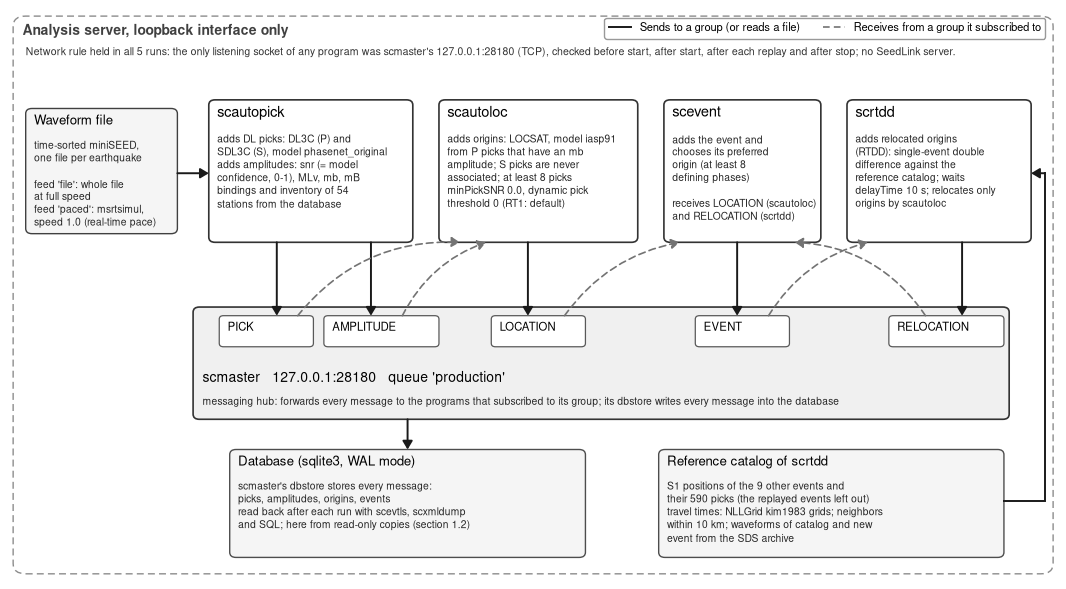

subscriptions: {'scautopick': ['CONFIG'], 'scautoloc': ['PICK', 'AMPLITUDE'], 'scevent': ['LOCATION', 'RELOCATION', 'MAGNITUDE', 'FOCMECH', 'EVENT'], 'scrtdd': ['SERVICE_REQUEST', 'EVENT', 'LOCATION', 'PICK']}


In [6]:
# Figure 1: the data flow, built from the main run's own option dumps
OPT = R[MAIN_RUN]["options"]
CS = OPT["config_stack_per_module"]


def cfg(mod, key):
    v = CS[mod]["set"].get(key)
    return v["values"] if v else None


def runtime_dict(lines):
    out = {}
    for l in lines:
        m = re.match(r"^\s+(\S.*?)\s{2,}(\S.*)$", l)
        if m:
            out[m.group(1).strip()] = m.group(2).strip()
    return out


AL = runtime_dict(OPT["scautoloc_runtime"])
SET = R[MAIN_RUN]["settings"]["cfg_file_values"]
MO = OPT["scrtdd_resolved"]["module_options"]
PO = OPT["scrtdd_resolved"]["profile_options"]
FLOW = dict(
    bind=cfg("scmaster", "interface.bind")[0], queue=cfg("scmaster", "queues")[0],
    dbdriver=cfg("scmaster", "queues.production.processors.messages.dbstore.driver")[0],
    pick_group=cfg("scautopick", "connection.primaryGroup")[0], amp_group=cfg("scautopick", "connection.amplitudeGroup")[0],
    loc_group=cfg("scautoloc", "connection.primaryGroup")[0], loc_subs=cfg("scautoloc", "connection.subscriptions"),
    ev_group=cfg("scevent", "connection.primaryGroup")[0], ev_subs=cfg("scevent", "connection.subscriptions"),
    dd_group=cfg("scrtdd", "connection.primaryGroup")[0], dd_subs=cfg("scrtdd", "connection.subscriptions"),
    picker=SET["picker"], spicker=SET["spicker"], amps=SET["amplitudes"],
    model=os.path.basename(SET["module.trunk.global.picker.DL3C.model"]).replace(".onnx", ""),
    loc_profile=AL["profile"], min_phase=AL["minPhaseCount"], min_snr=AL["minPickSNR"], dyn=AL["dynamicPickThresholdInterval"],
    ev_minph=cfg("scevent", "eventAssociation.minimumDefiningPhases")[0],
    delay=MO["performance.delayTime"]["value"], authors=", ".join(x.split("@")[0] for x in MO["acceptedOriginAuthors"]["value"]),  # module names; host part omitted
    table=f"{PO['tableType']['value']} {PO['tableModel']['value']}",
    maxdist=PO["doubleDifferenceSystem.eventPairSelection.singleEvent.maxNeighbourDistance"]["value"],
    recordstream=cfg("scrtdd", "recordstream")[0] if cfg("scrtdd", "recordstream") else cfg("scautoloc", "recordstream")[0],
    n_sta=COMP[MAIN_RUN]["db_counts"]["Station"])
for k_, v_ in FLOW.items():
    print(f"  {k_:13s} {v_}")
# the dashed (subscription) arrows drawn below must be what the configuration says
assert {FLOW["pick_group"], FLOW["amp_group"]} <= set(FLOW["loc_subs"])
assert {FLOW["loc_group"], FLOW["dd_group"]} <= set(FLOW["ev_subs"])
assert FLOW["ev_group"] in FLOW["dd_subs"]

# network records of every run: before start, after start, after each replay, after stop
NET = []
for run in RUNS:
    d = f"{RT_ROOT}/{run}/network"
    others = []
    for f in sorted(glob.glob(f"{d}/after_*.txt")):
        if os.path.basename(f) == "after_stop.txt":
            continue
        m = re.search(r"# sockets other than (\S+): (\[.*\])", open(f).read())
        others.append(m.group(2) if m else "missing")
    st = json.load(open(f"{d}/after_stop.json"))
    NET.append({"Run": run, "Records checked": len(others),
                "Only scmaster's socket listening": all(x == "[]" for x in others),
                "Port free after stop": st["ss_port"] == [], "All recorded PIDs gone": all(st["pid_gone"].values()),
                "No module process left": all(len(v) == 0 for v in st["pgrep_x_this_user"].values()),
                "~/.seiscomp created": st["user_dot_seiscomp_exists"]})
NET = pd.DataFrame(NET)
display(NET)
NET_OK = bool(NET["Only scmaster's socket listening"].all() and NET["Port free after stop"].all()
              and NET["All recorded PIDs gone"].all() and NET["No module process left"].all()
              and not NET["~/.seiscomp created"].any())
speeds = sorted({x["feed_argv"][x["feed_argv"].index("-s") + 1] for run in RUNS for x in R[run]["replays"] if x.get("feed_argv")})

fig, ax = plt.subplots(figsize=(13.5, 7.4))
ax.set_xlim(0, 100)
ax.set_ylim(0, 66)
ax.axis("off")
# Server A / loopback frame
h4.box(ax, 0.3, 0.6, 99.4, 64.6, "", fc="none", ec="0.55", lw=1.0, ls=(0, (5, 3)), radius=1.2)
ax.text(1.2, 64.3, "Analysis server, loopback interface only", ha="left", va="top", fontsize=10, color="0.25", weight=BOLD)
# top row: programs
YT, HT = 39.0, 16.5
h4.box(ax, 1.5, YT + 1.0, 14.5, HT - 2.0, "Waveform file",
       "time-sorted miniSEED,\none file per earthquake\n\nfeed 'file': whole file\nat full speed\n"
       f"feed 'paced': msrtsimul,\nspeed {', '.join(speeds)} (real-time pace)", fc="0.96", title_size=9.5, body_size=7.4)
MODS = [("scautopick", 19.0, 19.5,
         f"adds DL picks: {FLOW['picker']} (P) and\n{FLOW['spicker']} (S), model {FLOW['model']}\n"
         f"adds amplitudes: snr (= model\nconfidence, 0-1), {FLOW['amps']}\n"
         f"bindings and inventory of {FLOW['n_sta']}\nstations from the database"),
        ("scautoloc", 41.0, 19.0,
         f"adds origins: LOCSAT, model {FLOW['loc_profile']}\nfrom P picks that have an mb\namplitude; "
         f"S picks are never\nassociated; at least {FLOW['min_phase']} picks\n"
         f"minPickSNR {FLOW['min_snr']}, dynamic pick\nthreshold {FLOW['dyn']} (RT1: default)"),
        ("scevent", 62.5, 15.0,
         f"adds the event and\nchooses its preferred\norigin (at least {FLOW['ev_minph']}\ndefining phases)\n\n"
         f"receives {FLOW['loc_group']} (scautoloc)\nand {FLOW['dd_group']} (scrtdd)"),
        ("scrtdd", 80.0, 17.6,
         f"adds relocated origins\n(RTDD): single-event double\ndifference against the\nreference catalog; waits\n"
         f"delayTime {FLOW['delay']} s; relocates only\norigins by {FLOW['authors']}")]
for name, x0, w, body in MODS:
    h4.box(ax, x0, YT, w, HT, name, body, fc="white", ec="0.2", lw=1.2, title_size=10.5, body_size=7.4)
# scmaster bus: the groups along its top edge, its name and job along its bottom edge
YB, HB = 18.5, 13.0
h4.box(ax, 17.5, YB, 78.0, HB, "", fc="0.94", ec="0.2", lw=1.2)
ax.text(18.4, YB + 5.6, f"scmaster   {FLOW['bind']}   queue '{FLOW['queue']}'", fontsize=10, ha="left", va="top", zorder=3)
ax.text(18.4, YB + 2.6, "messaging hub: forwards every message to the programs that subscribed to its group; "
        "its dbstore writes every message into the database", fontsize=7.4, ha="left", va="top", color="0.15", zorder=3)
GW, GH = 9.0, 3.6
GY = YB + HB - GH - 1.0
GROUPS = {FLOW["pick_group"]: 20.0, FLOW["amp_group"]: 30.0, FLOW["loc_group"]: 46.0, FLOW["ev_group"]: 65.5,
          FLOW["dd_group"]: 84.0}
for g, gx in GROUPS.items():
    h4.box(ax, gx, GY, GW + (2.0 if len(g) > 8 else 0.0), GH, g, fc="white", ec="0.35", lw=0.9, title_size=8.2, radius=0.4)
gc = {g: gx + (GW + (2.0 if len(g) > 8 else 0.0)) / 2 for g, gx in GROUPS.items()}
top_g = GY + GH
pub = dict(color="0.1", lw=1.4)
sub_ = dict(color="0.45", lw=1.2, ls=(0, (4, 2.5)))
h4.arrow(ax, (16.0, YT + 8.0), (19.0, YT + 8.0), **pub)
h4.arrow(ax, (gc[FLOW["pick_group"]] + 1.0, YT), (gc[FLOW["pick_group"]] + 1.0, top_g), **pub)
h4.arrow(ax, (gc[FLOW["amp_group"]] - 1.0, YT), (gc[FLOW["amp_group"]] - 1.0, top_g), **pub)
h4.arrow(ax, (gc[FLOW["pick_group"]] + 3.0, top_g), (43.0, YT), rad=-0.25, **sub_)
h4.arrow(ax, (gc[FLOW["amp_group"]] + 2.0, top_g), (45.5, YT), rad=-0.2, **sub_)
h4.arrow(ax, (gc[FLOW["loc_group"]] - 1.0, YT), (gc[FLOW["loc_group"]] - 1.0, top_g), **pub)
h4.arrow(ax, (gc[FLOW["loc_group"]] + 2.5, top_g), (64.0, YT), rad=-0.2, **sub_)
h4.arrow(ax, (gc[FLOW["ev_group"]] - 0.5, YT), (gc[FLOW["ev_group"]] - 0.5, top_g), **pub)
h4.arrow(ax, (gc[FLOW["ev_group"]] + 2.5, top_g), (82.0, YT), rad=-0.2, **sub_)
h4.arrow(ax, (gc[FLOW["dd_group"]] + 1.5, YT), (gc[FLOW["dd_group"]] + 1.5, top_g), **pub)
h4.arrow(ax, (gc[FLOW["dd_group"]] - 2.0, top_g), (75.0, YT), rad=0.25, **sub_)
# bottom row: database and reference catalog
h4.box(ax, 21.0, 2.5, 34.0, 12.5, f"Database ({FLOW['dbdriver']}, WAL mode)",
       "scmaster's dbstore stores every message:\npicks, amplitudes, origins, events\n"
       "read back after each run with scevtls, scxmldump\nand SQL; here from read-only copies (section 1.2)",
       fc="0.96", ec="0.3", title_size=9.5, body_size=7.4)
h4.arrow(ax, (38.0, YB), (38.0, 15.0), **pub)
h4.box(ax, 62.0, 2.5, 33.0, 12.5, "Reference catalog of scrtdd",
       f"S1 positions of the {N_CAT_EV} other events and\ntheir {N_CAT_PICKS} picks (the replayed events left out)\n"
       f"travel times: {FLOW['table']} grids; neighbors\nwithin {FLOW['maxdist']:g} km; waveforms of catalog and new\n"
       "event from the SDS archive", fc="0.96", ec="0.3", title_size=9.5, body_size=7.4)
ax.plot([95.0, 98.9, 98.9], [9.0, 9.0, YT + 8.0], color="0.1", lw=1.4, zorder=4, solid_joinstyle="miter")
h4.arrow(ax, (98.9, YT + 8.0), (97.6, YT + 8.0), **pub)
net_txt = (f"Network rule held in all {len(NET)} runs: the only listening socket of any program was scmaster's {FLOW['bind']} "
           f"(TCP), checked before start, after start, after each replay and after stop; no SeedLink server.") if NET_OK else \
          "Network check FAILED in at least one run (see the table above)."
ax.text(1.5, 61.6, net_txt, fontsize=7.6, color="0.2", ha="left", va="top")
handles = [Line2D([], [], **pub), Line2D([], [], **sub_)]
labels = ["Sends to a group (or reads a file)", "Receives from a group it subscribed to"]
ax.legend(handles, labels, loc="upper right", bbox_to_anchor=(0.995, 0.995), ncol=2, fontsize=8)
FIGS = {}
FIGS["1"] = h4.save_fig(fig, FIG_DIR, "04_1_data_flow", dpi=DPI)
plt.show()
print("subscriptions:", {m: cfg(m, "connection.subscriptions") for m in ("scautopick", "scautoloc", "scevent", "scrtdd")})

## 3. Figure 2: latency in the paced runs

**What the figure shows.** For the two runs fed at real-time pace (RT3_paced and RT5_paced_creationtime) and both
earthquakes, every object the chain made, placed at the time it was created:

- top three bands, one line per pick: a hollow dot where the wave arrived (the pick time) and a filled dot when
  the DL picker reported it; the line between them is the picker's waiting time. The mb band joins each P pick's
  creation to the creation of its mb amplitude (scautoloc cannot use a P pick before that). Picks are sorted by
  arrival time within each band; gray P picks were never used by any origin. The black bar below each band is a
  typical case: it starts at the median arrival (or pick) time and is as long as the median wait;
- the scautoloc origins (labeled with their number of P picks), the scevent event, and scrtdd: a light bar while
  it waits for the preferred origin to stay unchanged (delayTime), a dark bar while it computes, then the relocated
  origin (labeled with its 3-D distance from S1) or a black cross for a failed attempt.

**Time reference.** The horizontal axis counts seconds after the *final scautoloc (LOCSAT) origin time*, the
reference first reported in note 10: creation times (wall clock) are mapped to data time with the median release
offset of msrtsimul's records, and pick times are data times. The dotted line marks the alternative reference:
S1's origin time on msrtsimul's own clock. The panel on the right of each row lists the key times in both
references (the alternative in brackets), read from `results/delays.csv`. The right part of the time axis
(195 to 292 s) is drawn at a compressed scale; it holds the late scautoloc
updates, which come from scautoloc's playback clock and not from the data (section 4.5 of note 10).

In [7]:
# Figure 2 data: every pick, amplitude, origin and relocation of the paced runs, in seconds after the final LOCSAT origin time
REL_ROW = {}


def timeline(run, k):
    dl = R[run]["delays"].set_index("kma_id").loc[k]
    hyp_ot = UTCDateTime(dl.final_scautoloc_origin_time)
    ow = UTCDateTime(dl.origin_time_wall)                       # final LOCSAT origin time on the wall clock (rt_analyze.py)
    s1w = UTCDateTime(dl.S1_origin_time_wall_msrtsimul_clock)   # S1 origin time on msrtsimul's clock
    pk = DB[run]["picks"]
    sub = pk[[(t > KMA_OT[k] + PICK_WINDOW_S[0]) and (t < KMA_OT[k] + PICK_WINDOW_S[1]) for t in pk.t]].copy()
    sub["onset_s"] = [t - hyp_ot for t in sub.t]
    sub["created_s"] = [c - ow for c in sub.created]
    org = DB[run]["origins"]
    org = org[org.kma_id == k].sort_values("created").copy()
    org["created_s"] = [c - ow for c in org.created]
    arr = DB[run]["arrivals"]
    sub["used"] = sub.publicID.isin(set(arr[arr.originID.isin(org.publicID)].pickID))
    amp = DB[run]["amplitudes"]
    mb = amp[(amp.type == "mb") & amp.pickID.isin(sub.publicID)].copy()
    mb["created_s"] = [c - ow for c in mb.created]
    mb = mb.merge(sub[["publicID", "created_s", "onset_s"]].rename(
        columns={"publicID": "pickID", "created_s": "pick_created_s", "onset_s": "pick_onset_s"}), on="pickID")
    ev = DB[run]["events"]
    evid = R[run]["origins"][R[run]["origins"].kma_id == k].eventID.iloc[0]
    ev_created_s = float(ev[ev.publicID == evid].created.iloc[0] - ow)
    rel = R[run]["scrtdd_relocations"]
    pos = R[run]["positions_vs_reference"]
    att = []
    for _, b in rel[rel.input_origin.isin(org.publicID)].iterrows():
        src = org[org.publicID == b.input_origin].iloc[0]
        a = dict(input=b.input_origin, n_P=int(src.n_arr_P), input_created_s=float(src.created_s),
                 start_s=UTCDateTime(b.t_start) - ow)
        out_id = b.get("output_origin")
        if isinstance(out_id, str):
            out = org[org.publicID == out_id].iloc[0]
            p = pos[(pos.origin == out_id) & (pos.versus == "S1") & (pos.kind == "absolute")]
            a.update(ok=True, end_s=float(out.created_s), output=out_id, d3D_S1_m=float(p.d3D_m.iloc[0]))
        else:
            a.update(ok=False, end_s=RA.t_log(str(b.step2_failed)) - ow, output=None, d3D_S1_m=np.nan)
        att.append(a)
    loc = org[org.methodID == "LOCSAT"]
    out = dict(run=run, k=k, dl=dl, picks=sub, mb=mb, loc=loc, ev_created_s=ev_created_s, att=pd.DataFrame(att),
               s1_ref_s=float(s1w - ow), shift_set2_s=float(s1w - ow))
    # checks against the file values (rt_analyze.py's own latencies)
    assert abs(sub.created_s.min() - dl.latency_first_DL_pick_created_after_origin_time_s) < 1e-3
    assert abs(loc.created_s.iloc[0] - dl.latency_first_origin_created_after_origin_time_s) < 1e-3
    assert abs(ev_created_s - dl.latency_event_created_after_origin_time_s) < 1e-3
    okat = out["att"][out["att"].ok]
    assert abs(okat.end_s.iloc[0] - dl.latency_RTDD_1_created_after_origin_time_s) < 1e-3
    assert abs((loc.created_s.iloc[0] - out["shift_set2_s"]) - dl.latency_first_origin_created_after_S1_origin_time_msrtsimul_clock_s) < 1e-3
    return out


TL = {(run, k): timeline(run, k) for run in PACED_RUNS for k in REPLAYED}
rows = []
for (run, k), T in TL.items():
    p = T["picks"]
    P = p[p.methodID == "DL3C"]
    S = p[p.methodID == "SDL3C"]
    first = p.sort_values("created_s").iloc[0]
    first_after = p[p.onset_s > 0].sort_values("created_s").iloc[0]
    rows.append({"Run": run, "Event": RID[k], "DL picks (P / S)": f"{len(P)} / {len(S)}",
                 "P picks used by an origin": int(P.used.sum()), "S picks used": int(S.used.sum()),
                 "First DL pick: station, method": f"{first.waveformID_stationCode} {first.methodID}",
                 "its pick time after the origin (s)": round(first.onset_s, 2),
                 "its creation (s)": round(first.created_s, 3),
                 "First pick timed after the origin: creation (s)": round(first_after.created_s, 3),
                 "mb amplitude after its P pick, median (s)": round(float((T["mb"].created_s - T["mb"].pick_created_s).median()), 3),
                 "Picks outside both time windows": int(((p.created_s > TIMELINE_EARLY_S[1]) & (p.created_s < TIMELINE_LATE_S[0])).sum()
                                                        + (p.onset_s < TIMELINE_EARLY_S[0]).sum())})
PICKTAB = pd.DataFrame(rows)
display(PICKTAB)
MB_MED = {(r_["Run"], r_["Event"]): r_["mb amplitude after its P pick, median (s)"] for r_ in rows}
MB_POOLED = {run: float(pd.concat([TL[(run, k)]["mb"].created_s - TL[(run, k)]["mb"].pick_created_s for k in REPLAYED]).median())
             for run in PACED_RUNS}
print("mb amplitude after its P pick, median over both events:", {r_: round(v_, 3) for r_, v_ in MB_POOLED.items()})

,Run,Event,DL picks (P / S),P picks used by an origin,S picks used,"First DL pick: station, method",its pick time after the origin (s),its creation (s),First pick timed after the origin: creation (s),"mb amplitude after its P pick, median (s)",Picks outside both time windows
0,RT3_paced,3,56 / 56,55,0,HAMB DL3C,10.37,15.071,15.071,14.045,0
1,RT3_paced,9,43 / 42,37,0,HCNA DL3C,-20.08,13.256,15.257,14.010,0
2,RT5_paced_creationtime,3,56 / 56,55,0,HAMB DL3C,10.37,15.071,15.071,14.293,0
3,RT5_paced_creationtime,9,43 / 42,37,0,HCNA DL3C,-20.08,13.256,15.258,14.010,0


mb amplitude after its P pick, median over both events: {'RT3_paced': 14.014, 'RT5_paced_creationtime': 14.017}


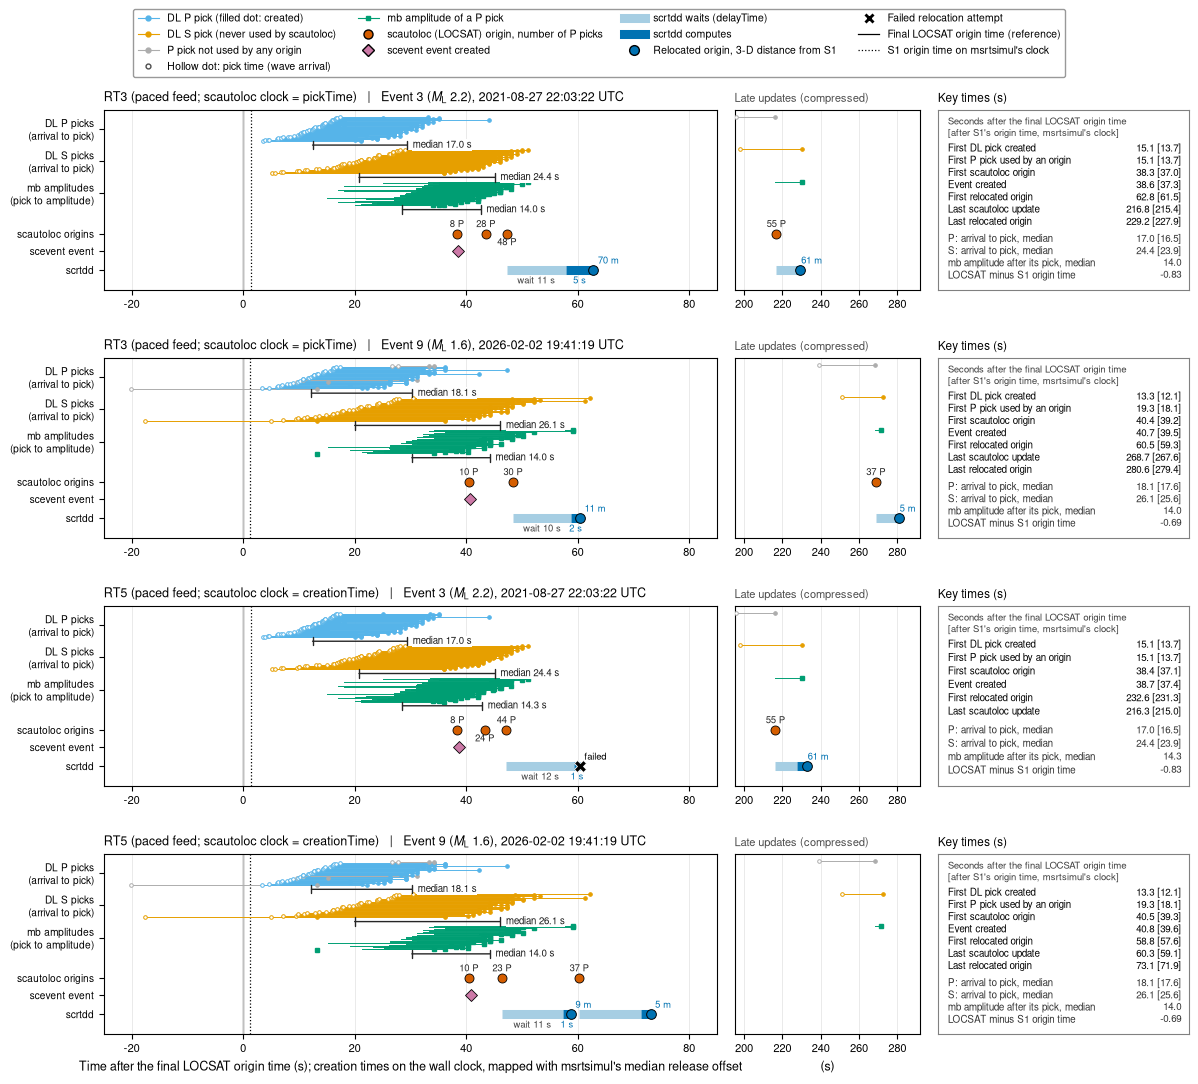

In [8]:
# Figure 2: the timeline
BAND = {"P": 5.0, "S": 4.0, "mb": 3.0}
BAND_H = 0.74
Y_ORIG, Y_EVENT, Y_DD = 2.12, 1.58, 1.0
YTICKS = [BAND["P"] + BAND_H / 2, BAND["S"] + BAND_H / 2, BAND["mb"] + BAND_H / 2, Y_ORIG, Y_EVENT, Y_DD]
YLABELS = ["DL P picks\n(arrival to pick)", "DL S picks\n(arrival to pick)", "mb amplitudes\n(pick to amplitude)",
           "scautoloc origins", "scevent event", "scrtdd"]


def draw_timeline(ax, T, late=False):
    p = T["picks"]
    for ph, meth in (("P", "DL3C"), ("S", "SDL3C")):
        q = p[p.methodID == meth].sort_values("onset_s").reset_index(drop=True)
        n = max(len(q) - 1, 1)
        for i, r_ in q.iterrows():
            y = BAND[ph] + BAND_H * i / n
            c = COL[ph] if (ph == "S" or r_.used) else COL["unused"]
            ax.plot([r_.onset_s, r_.created_s], [y, y], color=c, lw=0.7, zorder=2)
            ax.plot(r_.onset_s, y, "o", ms=2.6, mfc="white", mec=c, mew=0.7, zorder=3)
            ax.plot(r_.created_s, y, "o", ms=2.6, mfc=c, mec=c, mew=0.7, zorder=3)
        if ph == "P":
            order = dict(zip(q.publicID, range(len(q))))
            npk = n
    for _, r_ in T["mb"].iterrows():
        y = BAND["mb"] + BAND_H * order.get(r_.pickID, 0) / npk
        ax.plot([r_.pick_created_s, r_.created_s], [y, y], color=COL["mb"], lw=0.7, zorder=2)
        ax.plot(r_.created_s, y, "s", ms=2.4, mfc=COL["mb"], mec=COL["mb"], zorder=3)
    prev = -1e9
    for _, o in T["loc"].iterrows():
        ax.plot(o.created_s, Y_ORIG, "o", ms=6.5, mfc=COL["locsat"], mec="k", mew=0.6, zorder=4)
        below = o.created_s - prev < 5.0                                # close to the previous label: write it below
        ax.text(o.created_s, Y_ORIG + (-0.13 if below else 0.13), f"{int(o.n_arr_P)} P", ha="center", va="top" if below else "bottom",
                fontsize=6.8, color="0.15", zorder=5, clip_on=True)
        prev = -1e9 if below else o.created_s
    ax.plot(T["ev_created_s"], Y_EVENT, "D", ms=6, mfc=COL["event"], mec="k", mew=0.6, zorder=4)
    for _, a in T["att"].iterrows():
        ax.plot([a.input_created_s, a.start_s], [Y_DD, Y_DD], color=COL["wait"], lw=6.5, solid_capstyle="butt", zorder=2)
        ax.plot([a.start_s, a.end_s], [Y_DD, Y_DD], color=COL["rtdd"], lw=6.5, solid_capstyle="butt", zorder=2)
        if a.ok:
            ax.plot(a.end_s, Y_DD, "o", ms=7, mfc=COL["rtdd"], mec="k", mew=0.7, zorder=4)
            ax.text(a.end_s + (0.8 if not late else 0.6), Y_DD + 0.12, f"{a.d3D_S1_m:.0f} m", ha="left", va="bottom",
                    fontsize=6.8, color=COL["rtdd"], clip_on=True, zorder=5)
        else:
            ax.plot(a.end_s, Y_DD, "X", ms=8.5, mfc=COL["fail"], mec="white", mew=0.6, zorder=4)
            ax.text(a.end_s + 0.8, Y_DD + 0.12, "failed", ha="left", va="bottom", fontsize=6.8, clip_on=True, zorder=5)
    ax.axvline(0.0, color="k", lw=0.9, zorder=1)
    ax.axvline(T["s1_ref_s"], color="k", lw=0.9, ls=":", zorder=1)
    ax.set_ylim(0.38, 5.95)
    ax.set_yticks(YTICKS)
    ax.grid(axis="x", color="0.9", lw=0.6, zorder=0)
    h4.close_box(ax)


def dimension(ax, x0, x1, y, text, color):
    # a typical pick: from the median arrival time, the median waiting time; drawn in the gap below its band
    ax.annotate("", xy=(x1, y), xytext=(x0, y), arrowprops=dict(arrowstyle="|-|", color="0.15", lw=1.0, shrinkA=0, shrinkB=0,
                                                                mutation_scale=3), zorder=6)
    ax.text(x1 + 1.0, y, text, ha="left", va="center", fontsize=7, color="0.1", zorder=7,
            bbox=dict(fc="white", ec="none", pad=0.3, alpha=1.0))


def panel_text(ax, T):
    dl = T["dl"]
    lines = [("First DL pick created", "latency_first_DL_pick_created_after_origin_time_s",
              "latency_first_DL_pick_created_after_S1_origin_time_msrtsimul_clock_s"),
             ("First P pick used by an origin", "latency_first_used_pick_created_after_origin_time_s",
              "latency_first_used_pick_created_after_S1_origin_time_msrtsimul_clock_s"),
             ("First scautoloc origin", "latency_first_origin_created_after_origin_time_s",
              "latency_first_origin_created_after_S1_origin_time_msrtsimul_clock_s"),
             ("Event created", "latency_event_created_after_origin_time_s",
              "latency_event_created_after_S1_origin_time_msrtsimul_clock_s"),
             ("First relocated origin", "latency_RTDD_1_created_after_origin_time_s",
              "latency_RTDD_1_created_after_S1_origin_time_msrtsimul_clock_s"),
             ("Last scautoloc update", "latency_final_scautoloc_origin_created_after_origin_time_s",
              "latency_final_scautoloc_origin_created_after_S1_origin_time_msrtsimul_clock_s")]
    n_rt = int(dl.n_RTDD_origins)
    if n_rt > 1:
        lines.append(("Last relocated origin", f"latency_RTDD_{n_rt}_created_after_origin_time_s",
                      f"latency_RTDD_{n_rt}_created_after_S1_origin_time_msrtsimul_clock_s"))
    extra = [("P: arrival to pick, median", f"{dl.DL3C_latency_after_pick_time_median_s:.1f} [{dl.DL3C_latency_after_pick_time_msrtsimul_clock_median_s:.1f}]"),
             ("S: arrival to pick, median", f"{dl.SDL3C_latency_after_pick_time_median_s:.1f} [{dl.SDL3C_latency_after_pick_time_msrtsimul_clock_median_s:.1f}]"),
             ("mb amplitude after its pick, median", f"{MB_MED[(T['run'], RID[T['k']])]:.1f}"),
             ("LOCSAT minus S1 origin time", f"{dl.final_scautoloc_origin_time_minus_S1_s:+.2f}")]
    y = 0.965
    ax.text(0.04, y, "Seconds after the final LOCSAT origin time\n[after S1's origin time, msrtsimul's clock]",
            transform=ax.transAxes, fontsize=6.9, va="top", ha="left", color="0.25")
    y -= 0.15
    step = (y - 0.04) / (len(lines) + len(extra) + 0.4)               # line spacing from the number of lines
    for lab, c1, c2 in lines:
        ax.text(0.04, y, lab, transform=ax.transAxes, fontsize=7.1, va="top", ha="left")
        ax.text(0.97, y, f"{float(dl[c1]):.1f} [{float(dl[c2]):.1f}]", transform=ax.transAxes, fontsize=7.1, va="top", ha="right")
        y -= step
    y -= 0.4 * step
    for lab, val in extra:
        ax.text(0.04, y, lab, transform=ax.transAxes, fontsize=7.1, va="top", ha="left", color="0.2")
        ax.text(0.97, y, val, transform=ax.transAxes, fontsize=7.1, va="top", ha="right", color="0.2")
        y -= step
    ax.set_xticks([])
    ax.set_yticks([])
    h4.close_box(ax, color="0.5")


PANELS = list(TL.keys())
nrow = len(PANELS)
fig = plt.figure(figsize=(14.0, 3.0 * nrow))
gs = GridSpec(nrow, 3, width_ratios=[3.3, 1.0, 1.35], wspace=0.05, hspace=0.38, figure=fig)
AXE = []
for i, key in enumerate(PANELS):
    T = TL[key]
    run, k = key
    axE = fig.add_subplot(gs[i, 0])
    axL = fig.add_subplot(gs[i, 1], sharey=axE)
    axT = fig.add_subplot(gs[i, 2])
    draw_timeline(axE, T)
    draw_timeline(axL, T, late=True)
    axE.set_xlim(*TIMELINE_EARLY_S)
    axL.set_xlim(*TIMELINE_LATE_S)
    axE.set_yticklabels(YLABELS, fontsize=7.3)
    plt.setp(axL.get_yticklabels(), visible=False)
    axL.tick_params(axis="y", length=0)
    timing = R[run]["variant"].get("autoloc_timing") or runtime_dict(R[run]["options"]["scautoloc_runtime"])["timing"]
    axE.set_title(f"{run.split('_')[0]} (paced feed; scautoloc clock = {timing})   |   {evlabel(k)}, "
                  f"{KMA_OT[k].strftime('%Y-%m-%d %H:%M:%S')} UTC", loc="left", fontsize=9)
    axL.set_title("Late updates (compressed)", loc="left", fontsize=8, color="0.3")
    # dimension lines: median picker wait (P, S), median mb wait, first scrtdd wait and computing
    p = T["picks"]
    gap = 1.0 - BAND_H
    for ph, meth, col in (("P", "DL3C", "DL3C_latency_after_pick_time_median_s"), ("S", "SDL3C", "SDL3C_latency_after_pick_time_median_s")):
        q = p[(p.methodID == meth) & (p.onset_s > 0) & (p.onset_s < TIMELINE_EARLY_S[1])]
        med = float(T["dl"][col])
        x0 = float(q.onset_s.median())
        dimension(axE, x0, x0 + med, BAND[ph] - 0.5 * gap, f"median {med:.1f} s", COL[ph])
    mbw = MB_MED[(run, RID[k])]
    x0 = float(T["mb"][T["mb"].pick_onset_s > 0].pick_created_s.median())
    dimension(axE, x0, x0 + mbw, BAND["mb"] - 0.5 * gap, f"median {mbw:.1f} s", COL["mb"])
    a0 = T["att"].iloc[0]
    axE.text(0.5 * (a0.input_created_s + a0.start_s), Y_DD - 0.2, f"wait {a0.start_s - a0.input_created_s:.0f} s", ha="center", va="top",
             fontsize=6.8, color="0.25", clip_on=True)
    axE.text(0.5 * (a0.start_s + a0.end_s), Y_DD - 0.2, f"{a0.end_s - a0.start_s:.0f} s", ha="center", va="top", fontsize=6.8,
             color=COL["rtdd"], clip_on=True)
    panel_text(axT, T)
    axT.set_title("Key times (s)", loc="left", fontsize=8.5)
    if i == nrow - 1:
        axE.set_xlabel("Time after the final LOCSAT origin time (s); creation times on the wall clock, mapped with msrtsimul's median release offset")
        axL.set_xlabel("(s)")
    AXE += [axE, axL, axT]
handles = [(Line2D([], [], color=COL["P"], lw=0.8, marker="o", ms=3.5, mfc=COL["P"], mec=COL["P"])),
           Line2D([], [], color=COL["S"], lw=0.8, marker="o", ms=3.5, mfc=COL["S"], mec=COL["S"]),
           Line2D([], [], color=COL["unused"], lw=0.8, marker="o", ms=3.5, mfc=COL["unused"], mec=COL["unused"]),
           Line2D([], [], ls="none", marker="o", ms=3.5, mfc="white", mec="0.3"),
           Line2D([], [], color=COL["mb"], lw=0.8, marker="s", ms=3.2, mfc=COL["mb"], mec=COL["mb"]),
           Line2D([], [], ls="none", marker="o", ms=6.5, mfc=COL["locsat"], mec="k"),
           Line2D([], [], ls="none", marker="D", ms=6, mfc=COL["event"], mec="k"),
           Line2D([], [], color=COL["wait"], lw=6.5), Line2D([], [], color=COL["rtdd"], lw=6.5),
           Line2D([], [], ls="none", marker="o", ms=7, mfc=COL["rtdd"], mec="k"),
           Line2D([], [], ls="none", marker="X", ms=8, mfc=COL["fail"], mec="white"),
           Line2D([], [], color="k", lw=0.9), Line2D([], [], color="k", lw=0.9, ls=":")]
labels = ["DL P pick (filled dot: created)", "DL S pick (never used by scautoloc)", "P pick not used by any origin",
          "Hollow dot: pick time (wave arrival)", "mb amplitude of a P pick", "scautoloc (LOCSAT) origin, number of P picks",
          "scevent event created", "scrtdd waits (delayTime)", "scrtdd computes", "Relocated origin, 3-D distance from S1",
          "Failed relocation attempt", "Final LOCSAT origin time (reference)", "S1 origin time on msrtsimul's clock"]
h4.legend_above(fig, AXE, handles, labels, ncol=4, fontsize=7.6)
FIGS["2"] = h4.save_fig(fig, FIG_DIR, "04_2_latency_timeline", dpi=DPI)
plt.show()

In [9]:
# Figure 2, the numbers: both latency sets from results/delays.csv (paced runs)
LAT_ROWS = [("First DL pick created", "first_DL_pick_created"), ("First P pick used created", "first_used_pick_created"),
            ("First scautoloc origin", "first_origin_created"), ("Event created", "event_created"),
            ("First relocated origin", "RTDD_1_created"), ("Second relocated origin", "RTDD_2_created"),
            ("Last scautoloc update", "final_scautoloc_origin_created")]
tab = {}
for run in PACED_RUNS:
    dl = R[run]["delays"].set_index("kma_id")
    for k in REPLAYED:
        col = f"{run.split('_')[0]} event {RID[k]}"
        vals = []
        for lab, key in LAT_ROWS:
            a = dl.loc[k].get(f"latency_{key}_after_origin_time_s")
            b = dl.loc[k].get(f"latency_{key}_after_S1_origin_time_msrtsimul_clock_s")
            vals.append("-" if (a is None or pd.isna(a)) else f"{float(a):.1f} [{float(b):.1f}]")
        tab[col] = vals
LATTAB = pd.DataFrame(tab, index=[l for l, _ in LAT_ROWS])
display(Markdown("**Latencies in seconds after the final LOCSAT origin time [after S1's origin time on msrtsimul's clock]**"))
display(LATTAB)
d0 = R[PACED_RUNS[0]]["delays"].set_index("kma_id")
display(Markdown(
    "- The two references differ by a constant per event: the LOCSAT origin time is "
    + " and ".join(f"{d0.loc[k].final_scautoloc_origin_time_minus_S1_s:+.2f} s (event {RID[k]})" for k in REPLAYED)
    + " off S1's, and msrtsimul's clock lies "
    + " and ".join(f"{d0.loc[k].msrtsimul_clock_offset_minus_median_offset_s:.2f} s" for k in REPLAYED)
    + " above the median release offset; together the first set is "
    + " and ".join(f"{d0.loc[k].latency_first_origin_created_after_origin_time_s - d0.loc[k].latency_first_origin_created_after_S1_origin_time_msrtsimul_clock_s:.2f} s"
                   for k in REPLAYED) + " longer than the bracketed one.\n"
    f"- **Event 9's first DL pick is not a pick of this earthquake.** Its pick time lies "
    f"{abs(PICKTAB[(PICKTAB.Run == PACED_RUNS[0]) & (PICKTAB.Event == RID[REPLAYED[1]])]['its pick time after the origin (s)'].iloc[0]):.1f} s "
    "before the origin time (left of zero in the figure), so the 'first DL pick' latency of event 9 times a pick of something else "
    "(noise or another signal). The first pick timed after the origin was created at "
    + " and ".join(f"{PICKTAB[(PICKTAB.Run == run) & (PICKTAB.Event == RID[REPLAYED[1]])]['First pick timed after the origin: creation (s)'].iloc[0]:.1f} s ({run.split('_')[0]})"
                   for run in PACED_RUNS)
    + ", and the first P pick that an origin used at "
    + " and ".join(f"{float(R[run]['delays'].set_index('kma_id').loc[REPLAYED[1], 'latency_first_used_pick_created_after_origin_time_s']):.1f} s ({run.split('_')[0]})"
                   for run in PACED_RUNS) + ".\n"
    "- The late scautoloc updates of event 3 (both runs) and event 9 (RT3) were released only when the next pick of the "
    "stream arrived, minutes later (the isolated pick in the right part); in live operation scautoloc's clock is the wall clock and "
    "would not wait like this (note 10, section 4.5)."))

**Latencies in seconds after the final LOCSAT origin time [after S1's origin time on msrtsimul's clock]**

,RT3 event 3,RT3 event 9,RT5 event 3,RT5 event 9
First DL pick created,15.1 [13.7],13.3 [12.1],15.1 [13.7],13.3 [12.1]
First P pick used created,15.1 [13.7],19.3 [18.1],15.1 [13.7],19.3 [18.1]
First scautoloc origin,38.3 [37.0],40.4 [39.2],38.4 [37.1],40.5 [39.3]
Event created,38.6 [37.3],40.7 [39.5],38.7 [37.4],40.8 [39.6]
First relocated origin,62.8 [61.5],60.5 [59.3],232.6 [231.3],58.8 [57.6]
Second relocated origin,229.2 [227.9],280.6 [279.4],-,73.1 [71.9]
Last scautoloc update,216.8 [215.4],268.7 [267.6],216.3 [215.0],60.3 [59.1]


- The two references differ by a constant per event: the LOCSAT origin time is -0.83 s (event 3) and -0.69 s (event 9) off S1's, and msrtsimul's clock lies 0.50 s and 0.50 s above the median release offset; together the first set is 1.33 s and 1.19 s longer than the bracketed one.
- **Event 9's first DL pick is not a pick of this earthquake.** Its pick time lies 20.1 s before the origin time (left of zero in the figure), so the 'first DL pick' latency of event 9 times a pick of something else (noise or another signal). The first pick timed after the origin was created at 15.3 s (RT3) and 15.3 s (RT5), and the first P pick that an origin used at 19.3 s (RT3) and 19.3 s (RT5).
- The late scautoloc updates of event 3 (both runs) and event 9 (RT3) were released only when the next pick of the stream arrived, minutes later (the isolated pick in the right part); in live operation scautoloc's clock is the wall clock and would not wait like this (note 10, section 4.5).

## 4. Figure 3: positions

**What the figure shows.** For each earthquake (one row each), where the chain put it and where the offline
solutions put it, in map view (east-north) and in a depth section (east-depth). The two left panels are at km
scale: the scautoloc (LOCSAT) origins of the main run RT2_filefeed, labeled with their number of P picks, the
one scrtdd started from (larger), and the arrow from that start to the real-time relocation. The two right
panels zoom to the m scale around the cluster (the 9 reference events in gray, S1 positions): the final
real-time relocation, the relocations from earlier scautoloc versions in the paced runs, S1, and HypoDD dt.cc.
HypoDD's frame differs from S1's by a few hundred meters (printed in section 1.1), so in the zoom HypoDD is drawn
after matching the centroids of the 9 reference events (the *catalog-relative* comparison of note 10); in the km
panels it is drawn where it is. The arrow entering a zoom panel comes from the start, which lies outside. The
km-scale depth section is not to scale (its depth axis is compressed); the zoom panels are to scale.

In [10]:
# Figure 3 data: positions of every origin of the replayed events (database copies), and the references
def dist_s1(run, origin):
    p = R[run]["positions_vs_reference"]
    q = p[(p.origin == origin) & (p.versus == "S1") & (p.kind == "absolute")]
    return float(q.d3D_m.iloc[0])


P3 = {}
for k in REPLAYED:
    rid = RID[k]
    o = DB[MAIN_RUN]["origins"]
    o = o[o.kma_id == k].sort_values("created")
    loc = o[o.methodID == "LOCSAT"]
    rel = R[MAIN_RUN]["scrtdd_relocations"]
    final_out = rel[rel.input_origin.isin(loc.publicID) & rel.output_origin.notna()].iloc[-1]
    start = loc[loc.publicID == final_out.input_origin].iloc[0]
    rtdd = o[o.publicID == final_out.output_origin].iloc[0]
    early = []
    for run in PACED_RUNS:
        oo = DB[run]["origins"]
        oo = oo[oo.kma_id == k]
        rr = R[run]["scrtdd_relocations"]
        for _, b in rr[rr.input_origin.isin(oo.publicID)].iterrows():
            src = oo[oo.publicID == b.input_origin].iloc[0]
            # an earlier version = a start with fewer P picks than the main run's start (publicIDs differ between runs)
            if isinstance(b.get("output_origin"), str) and int(src.n_arr_P) < int(start.n_arr_P):
                x = oo[oo.publicID == b.output_origin].iloc[0]
                early.append(dict(run=run, E=x.E, N=x.N, U=x.U, n_P=int(src.n_arr_P), d3D_S1_m=dist_s1(run, x.publicID)))
    finals = []                                         # the last relocated origin of each run that has one
    for run in RUNS:
        oo = DB[run]["origins"]
        if len(oo):
            oo = oo[(oo.kma_id == k) & (oo.methodID == "RTDD")].sort_values("created")
            if len(oo):
                finals.append((run.split("_")[0], dist_s1(run, oo.publicID.iloc[-1])))
    xyz_start = start[["E", "N", "U"]].to_numpy(float)
    xyz_rtdd = rtdd[["E", "N", "U"]].to_numpy(float)
    P3[k] = dict(loc=loc, start=start, rtdd=rtdd, early=pd.DataFrame(early), s1=S1.loc[rid], hdd=HDD.loc[rid],
                 hdd_s1=HDD_S1FRAME.loc[rid], refs=S1.loc[REF_IDS],
                 d_start_rtdd=float(np.linalg.norm(xyz_start - xyz_rtdd)),
                 d_rtdd_s1=dist_s1(MAIN_RUN, rtdd.publicID), d_start_s1=dist_s1(MAIN_RUN, start.publicID),
                 d_hdd_rel=float(np.linalg.norm(xyz_rtdd - HDD_S1FRAME.loc[rid].to_numpy(float))),
                 finals=finals)

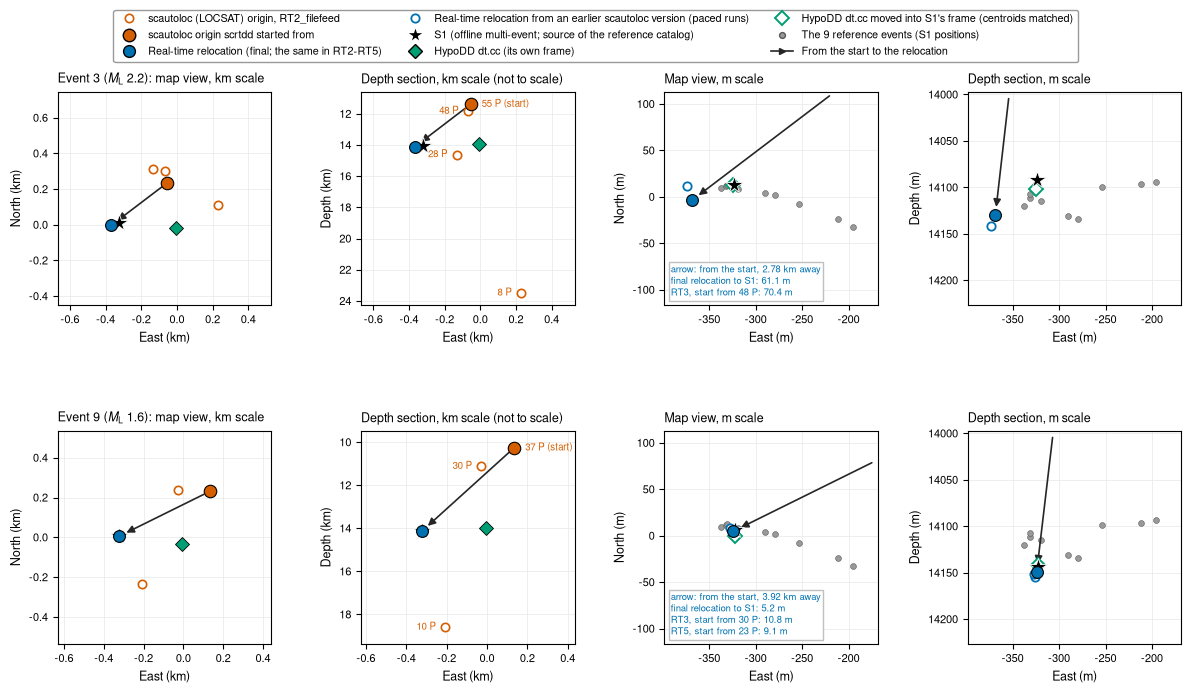

In [11]:
# Figure 3: map view and depth section, km scale and m scale
def mark(ax, x, y, kind, **kw):
    st = dict(s1=dict(marker="*", ms=13, mfc=COL["s1"], mec="white", mew=0.6),
              hdd=dict(marker="D", ms=7, mfc=COL["hypodd"], mec="k", mew=0.6),
              hdd_s1=dict(marker="D", ms=7, mfc="white", mec=COL["hypodd"], mew=1.4),
              start=dict(marker="o", ms=9, mfc=COL["locsat"], mec="k", mew=0.8),
              loc=dict(marker="o", ms=6, mfc="white", mec=COL["locsat"], mew=1.2),
              rtdd=dict(marker="o", ms=8.5, mfc=COL["rtdd"], mec="k", mew=0.8),
              early=dict(marker="o", ms=6, mfc="white", mec=COL["rtdd"], mew=1.3),
              ref=dict(marker="o", ms=4.2, mfc=COL["ref"], mec="0.35", mew=0.4))[kind]
    st.update(kw)
    ax.plot(x, y, ls="none", zorder=5 if kind not in ("ref",) else 3, **st)


def arrow3(ax, p0, p1, color="0.15"):
    ax.annotate("", xy=p1, xytext=p0, arrowprops=dict(arrowstyle="-|>", color=color, lw=1.2, shrinkA=5, shrinkB=6,
                                                       mutation_scale=11), zorder=4)


nev = len(REPLAYED)
fig = plt.figure(figsize=(14.5, 3.75 * nev))
gs = GridSpec(nev, 4, figure=fig, wspace=0.42, hspace=0.42)
AX3 = []
for i, k in enumerate(REPLAYED):
    D = P3[k]
    a1, a2, a3, a4 = (fig.add_subplot(gs[i, j]) for j in range(4))
    km = 1e-3
    # km scale: map view (E, N) and depth section (E, depth)
    for ax, yi, ysign in ((a1, "N", 1.0), (a2, "U", -1.0)):
        g = (lambda r_, c: r_[c] * km if c != "U" else -r_[c] * km)
        for _, o in D["loc"].iterrows():
            if o.publicID != D["start"].publicID:
                mark(ax, o.E * km, g(o, yi), "loc")
                if yi == "U":
                    ax.annotate(f"{int(o.n_arr_P)} P", (o.E * km, -o.U * km), xytext=(-7, 0), textcoords="offset points",
                                fontsize=7, va="center", ha="right", color=COL["locsat"])
        mark(ax, D["start"].E * km, g(D["start"], yi), "start")
        if yi == "U":
            ax.annotate(f"{int(D['start'].n_arr_P)} P (start)", (D["start"].E * km, -D["start"].U * km), xytext=(8, 0),
                        textcoords="offset points", fontsize=7, va="center", ha="left", color=COL["locsat"])
        mark(ax, D["hdd"].E * km, g(D["hdd"], yi), "hdd")
        mark(ax, D["s1"].E * km, g(D["s1"], yi), "s1")
        mark(ax, D["rtdd"].E * km, g(D["rtdd"], yi), "rtdd")
        arrow3(ax, (D["start"].E * km, g(D["start"], yi)), (D["rtdd"].E * km, g(D["rtdd"], yi)))
        xs = [D["start"].E] + list(D["loc"].E) + [D["s1"].E, D["hdd"].E, D["rtdd"].E]
        ys = [D["start"][yi]] + list(D["loc"][yi]) + [D["s1"][yi], D["hdd"][yi], D["rtdd"][yi]]
        ys = [ysign * y_ * km for y_ in ys]
        xl = (min(xs) * km - OVERVIEW_PAD_KM, max(xs) * km + OVERVIEW_PAD_KM)
        yl = (min(ys) - OVERVIEW_PAD_KM, max(ys) + OVERVIEW_PAD_KM)
        if yi == "N":
            half = 0.5 * max(xl[1] - xl[0], yl[1] - yl[0])
            ax.set_xlim(0.5 * sum(xl) - half, 0.5 * sum(xl) + half)
            ax.set_ylim(0.5 * sum(yl) - half, 0.5 * sum(yl) + half)
            ax.set_aspect("equal", adjustable="box")
            ax.set_ylabel("North (km)")
            ax.set_title(f"{evlabel(k)}: map view, km scale", loc="left", fontsize=9)
        else:
            ax.set_xlim(*xl)
            ax.set_ylim(yl[1] + 0.5, yl[0] - 0.5)
            ax.set_ylabel("Depth (km)")
            ax.set_title("Depth section, km scale (not to scale)", loc="left", fontsize=9)
        ax.set_xlabel("East (km)")
        if yi == "U":
            ax.set_box_aspect(1.0)
        ax.grid(color="0.92", lw=0.6, zorder=0)
        h4.close_box(ax)
    # m scale: map view and depth section around the centroid of the 9 reference events (S1)
    cx, cy, cz = C_S1.E, C_S1.N, -C_S1.U
    for ax, mode in ((a3, "map"), (a4, "depth")):
        if mode == "map":
            f = (lambda e, n, u: (e, n))
            ctr, hw, hh = (cx, cy), ZOOM_HALF_WIDTH_M, ZOOM_HALF_WIDTH_M
        else:
            f = (lambda e, n, u: (e, -u))
            ctr, hw, hh = (cx, cz), ZOOM_HALF_WIDTH_M, ZOOM_HALF_DEPTH_M
        r_ = D["refs"]
        mark(ax, *f(r_.E.to_numpy(), r_.N.to_numpy(), r_.U.to_numpy()), "ref")
        mark(ax, *f(D["hdd_s1"].E, D["hdd_s1"].N, D["hdd_s1"].U), "hdd_s1")
        mark(ax, *f(D["s1"].E, D["s1"].N, D["s1"].U), "s1")
        for _, e in D["early"].iterrows():
            mark(ax, *f(e.E, e.N, e.U), "early")
        x1, y1 = f(D["rtdd"].E, D["rtdd"].N, D["rtdd"].U)
        mark(ax, x1, y1, "rtdd")
        x0, y0 = f(D["start"].E, D["start"].N, D["start"].U)
        pe = h4.clip_to_box((x0, y0), (x1, y1), hw, hh, ctr)
        arrow3(ax, tuple(pe), (x1, y1))
        ax.set_xlim(ctr[0] - hw, ctr[0] + hw)
        if mode == "map":
            ax.set_ylim(ctr[1] - hh, ctr[1] + hh)
            ax.set_ylabel("North (m)")
            ax.set_title("Map view, m scale", loc="left", fontsize=9)
        else:
            ax.set_ylim(ctr[1] + hh, ctr[1] - hh)
            ax.set_ylabel("Depth (m)")
            ax.set_title("Depth section, m scale", loc="left", fontsize=9)
        ax.set_aspect("equal", adjustable="box")
        ax.set_xlabel("East (m)")
        ax.grid(color="0.92", lw=0.6, zorder=0)
        txt = [f"arrow: from the start, {D['d_start_rtdd'] / 1000:.2f} km away", f"final relocation to S1: {D['d_rtdd_s1']:.1f} m"] + [
            f"{e.run.split('_')[0]}, start from {e.n_P} P: {e.d3D_S1_m:.1f} m" for _, e in D["early"].iterrows()]
        if mode == "map":                                # the lower part of the map zoom is empty
            ax.text(0.03, 0.03, "\n".join(txt), transform=ax.transAxes, fontsize=6.8, ha="left", va="bottom", color=COL["rtdd"],
                    bbox=dict(fc="white", ec="0.75", pad=1.5, alpha=1.0), zorder=7)
        h4.close_box(ax)
    AX3 += [a1, a2, a3, a4]
handles = [Line2D([], [], ls="none", marker="o", ms=6, mfc="white", mec=COL["locsat"], mew=1.2),
           Line2D([], [], ls="none", marker="o", ms=9, mfc=COL["locsat"], mec="k"),
           Line2D([], [], ls="none", marker="o", ms=8.5, mfc=COL["rtdd"], mec="k"),
           Line2D([], [], ls="none", marker="o", ms=6, mfc="white", mec=COL["rtdd"], mew=1.3),
           Line2D([], [], ls="none", marker="*", ms=13, mfc=COL["s1"], mec="white"),
           Line2D([], [], ls="none", marker="D", ms=7, mfc=COL["hypodd"], mec="k"),
           Line2D([], [], ls="none", marker="D", ms=7, mfc="white", mec=COL["hypodd"], mew=1.4),
           Line2D([], [], ls="none", marker="o", ms=4.2, mfc=COL["ref"], mec="0.35"),
           Line2D([], [], color="0.15", lw=1.2, marker=">", ms=5)]
labels = [f"scautoloc (LOCSAT) origin, {MAIN_RUN}", "scautoloc origin scrtdd started from",
          "Real-time relocation (final; the same in RT2-RT5)", "Real-time relocation from an earlier scautoloc version (paced runs)",
          "S1 (offline multi-event; source of the reference catalog)", "HypoDD dt.cc (its own frame)",
          "HypoDD dt.cc moved into S1's frame (centroids matched)", "The 9 reference events (S1 positions)",
          "From the start to the relocation"]
h4.legend_above(fig, AX3, handles, labels, ncol=3, fontsize=7.8)
FIGS["3"] = h4.save_fig(fig, FIG_DIR, "04_3_positions", dpi=DPI)
plt.show()

In [12]:
# Figure 3, the numbers: positions and distances (absolute = as located; catalog-relative = HypoDD frame shift removed)
rows = []
for k in REPLAYED:
    D = P3[k]
    s1 = D["s1"]
    def row(name, e, n, u, d_file=None, note=""):
        d = float(np.linalg.norm([e - s1.E, n - s1.N, u - s1.U]))
        return {"Event": RID[k], "Solution": name, "East (m)": round(e, 1), "North (m)": round(n, 1), "Depth (m)": round(-u, 1),
                "3-D distance to S1 (m)": round(d, 1), "File value (m)": d_file, "Note": note}
    for _, o in D["loc"].iterrows():
        rows.append(row(f"scautoloc, {int(o.n_arr_P)} P" + (" (start)" if o.publicID == D["start"].publicID else ""),
                        o.E, o.N, o.U, dist_s1(MAIN_RUN, o.publicID) if o.publicID == D["start"].publicID else None))
    rows.append(row("Real-time relocation (RTDD, final)", D["rtdd"].E, D["rtdd"].N, D["rtdd"].U, D["d_rtdd_s1"],
                    "last relocation of each run: " + ", ".join(f"{r_} {x:.2f} m" for r_, x in D["finals"])))
    for _, e in D["early"].iterrows():
        rows.append(row(f"Real-time relocation from {e.n_P} P ({e.run.split('_')[0]})", e.E, e.N, e.U, e.d3D_S1_m))
    rows.append(row("S1", s1.E, s1.N, s1.U))
    rows.append(row("HypoDD dt.cc (own frame)", D["hdd"].E, D["hdd"].N, D["hdd"].U))
    rows.append(row("HypoDD dt.cc (S1's frame)", D["hdd_s1"].E, D["hdd_s1"].N, D["hdd_s1"].U))
POSTAB = pd.DataFrame(rows)
display(POSTAB)
kp = R[MAIN_RUN]["positions_vs_reference"]
for k in REPLAYED:
    q = kp[(kp.kma_id == k) & (kp.solution == "scautoloc_final") & (kp.versus == "S1") & (kp.kind == "absolute")].iloc[0]
    r_ = kp[(kp.kma_id == k) & (kp.solution == "RTDD_1") & (kp.versus == "HypoDD_dtcc") & (kp.kind == "catalog_relative")].iloc[0]
    print(f"event {RID[k]}: LOCSAT start vs S1: {q.dH_m:.0f} m horizontally, {q.dU_m:+.0f} m vertically (+ = too shallow), "
          f"origin time {q.dT_ms / 1000:+.2f} s; relocation moved it {P3[k]['d_start_rtdd'] / 1000:.2f} km; "
          f"relocation vs HypoDD dt.cc catalog-relative {r_.d3D_m:.1f} m (file), {P3[k]['d_hdd_rel']:.1f} m (here)")

,Event,Solution,East (m),North (m),Depth (m),3-D distance to S1 (m),File value (m),Note
0,3,"scautoloc, 8 P",229.1,108.3,23487.3,9412.2,NaN,
1,3,"scautoloc, 28 P",-131.7,314.0,14610.1,629.6,NaN,
2,3,"scautoloc, 48 P",-69.0,301.3,11826.9,2297.6,NaN,
3,3,"scautoloc, 55 P (start)",-54.4,234.9,11382.9,2731.5,2731.486,
4,3,"Real-time relocation (RTDD, final)",-368.6,-3.7,14130.0,61.1,61.053,"last relocation of each run: RT2 61.05 m, RT3 61.05 m, RT4 61.05 m..."
5,3,Real-time relocation from 48 P (RT3),-373.4,11.9,14141.7,70.4,70.400,
6,3,S1,-323.7,12.3,14091.9,0.0,NaN,
7,3,HypoDD dt.cc (own frame),-7.7,-20.3,13930.0,356.5,NaN,
8,3,HypoDD dt.cc (S1's frame),-324.8,13.2,14102.2,10.4,NaN,
9,9,"scautoloc, 10 P",-206.9,-237.0,18585.1,4449.0,NaN,


event 3: LOCSAT start vs S1: 349 m horizontally, +2709 m vertically (+ = too shallow), origin time -0.83 s; relocation moved it 2.78 km; relocation vs HypoDD dt.cc catalog-relative 54.6 m (file), 54.6 m (here)
event 9: LOCSAT start vs S1: 510 m horizontally, +3881 m vertically (+ = too shallow), origin time -0.69 s; relocation moved it 3.92 km; relocation vs HypoDD dt.cc catalog-relative 8.8 m (file), 8.8 m (here)


## 5. Figure 4: the five runs and the two failures

**What the figure shows.** (a) One row per run: how the data were fed, the settings that differ between runs, and
what each stage produced for event 3 and event 9 (the two numbers in a cell). Blue cells: the stage worked;
orange cells: it failed; gray: not applicable. (b) Why scautoloc made no origin in RT1_filefeed: each P
pick's DL confidence (stored as its "SNR") against the threshold scautoloc's dynamic pick check demanded, both
read from scautoloc's own log. (c) Why one relocation attempt failed in RT5_paced_creationtime: the double-difference
residuals of scrtdd's first step for the failed start (top) and for the same earthquake's next start (bottom).
scrtdd gives zero weight to residuals beyond a cut-off of 10 × MAD / 0.6745 (MAD: median absolute deviation), and
it measures the residuals *from zero*; the shaded band is the range it kept. Every residual of a new event shares
the error of its starting origin time, so a start whose origin time is about a second off, with a small spread,
leaves almost nothing inside the band. (d) All real-time relocation attempts of RT2-RT5: the share of double
differences beyond the cut-off against the summed weight that remained.

In [13]:
# Figure 4 data: the runs table, scautoloc's log of RT1, and scrtdd's first-step residuals
def outcome(run, k):
    e = COMP[run]["events"].get(k, {})
    replayed = any(x["event"] == k for x in R[run]["replays"])
    if not replayed:
        return None
    return e


def last_reloc_to_s1(run, k):
    # 3-D distance of the run's last relocated origin of event k from S1, from positions_vs_reference.csv (1 mm)
    o = DB[run]["origins"]
    if not len(o):
        return "-"
    o = o[(o.kma_id == k) & (o.methodID == "RTDD")].sort_values("created")
    return "-" if not len(o) else f"{dist_s1(run, o.publicID.iloc[-1]):.1f} m"


run_rows, cell_state = [], []
for run in RUNS:
    rt = runtime_dict(R[run]["options"]["scautoloc_runtime"])
    sev = R[run]["options"]["config_stack_per_module"]["scevent"]["set"].get("eventAssociation.priorities")
    feeds = sorted({x["feed"] for x in R[run]["replays"]})
    E = [outcome(run, k) for k in REPLAYED]

    def per_event(fn):
        return " | ".join("not replayed" if e is None else fn(e, k) for e, k in zip(E, REPLAYED))

    n_org = {k: (0 if e is None else e.get("n_scautoloc_origins", 0) or 0) for e, k in zip(E, REPLAYED)}
    row = {"Run": run.split("_")[0], "Feed": "/".join(feeds),
           "scautoloc clock": rt["timing"],
           "Dynamic pick check (s)": rt["dynamicPickThresholdInterval"],
           "scevent prefers": "scrtdd's origins" if (sev and sev["values"][0] == "AUTHOR") else "default",
           "DL picks P/S": per_event(lambda e, k: f"{e['n_DL3C']}/{e['n_SDL3C']}"),
           "Picks = step 09": per_event(lambda e, k: "yes" if e["picks_identical_to_step09"] else "no"),
           "scautoloc origins": per_event(lambda e, k: str(e.get("n_scautoloc_origins", 0))),
           "scrtdd attempts (failed)": per_event(lambda e, k: f"{e.get('scrtdd_attempts', 0)} ({e.get('scrtdd_failed_attempts', 0)})"),
           "Relocated origins": per_event(lambda e, k: str(e.get("n_RTDD_origins", 0))),
           "Preferred at end": per_event(lambda e, k: "-" if "preferred_is_RTDD" not in e else ("RTDD" if e["preferred_is_RTDD"] else "LOCSAT")),
           "Last relocation to S1": per_event(lambda e, k: last_reloc_to_s1(run, k))}
    failed_loc = any(e is not None and not e.get("n_scautoloc_origins") for e in E)
    failed_dd = any(e is not None and (e.get("scrtdd_failed_attempts") or 0) > 0 for e in E)
    n_fail = sum((e.get("scrtdd_failed_attempts") or 0) for e in E if e is not None)
    row["Outcome"] = ("stopped at scautoloc: no origin" if failed_loc else
                      (f"complete; {n_fail} failed relocation attempt" + ("s" if n_fail > 1 else "") if failed_dd else "complete"))
    run_rows.append(row)
RUNTAB = pd.DataFrame(run_rows)
display(RUNTAB)

# RT1: scautoloc's dynamic pick check, from its log
RX = re.compile(r"_tooManyRecentPicks: (\d{8}\.\d{6}\.\d+)-(\S+?)-\S*\s+(XX\s+)?pick SNR ([\d.]+) < ([\d.]+)")
lines = [l for l in open(f"{RT_ROOT}/{SCAUTOLOC_FAIL_RUN}/logs/scautoloc.log", errors="replace") if "_tooManyRecentPicks" in l]
rej = []
for l in lines:
    m = RX.search(l)
    if m:
        t = UTCDateTime(f"{m.group(1)[:4]}-{m.group(1)[4:6]}-{m.group(1)[6:8]}T{m.group(1)[9:11]}:{m.group(1)[11:13]}:{m.group(1)[13:15]}") \
            + float("0." + m.group(1).split(".")[2])
        rej.append(dict(t=t, stream=m.group(2), branch="XX" if m.group(3) else "weighted", snr=float(m.group(4)), threshold=float(m.group(5))))
REJ = pd.DataFrame(rej).sort_values("t").reset_index(drop=True)
db1 = DB[SCAUTOLOC_FAIL_RUN]
p1 = db1["picks"][db1["picks"].methodID == "DL3C"]
snr1 = db1["amplitudes"][(db1["amplitudes"].type == "snr") & db1["amplitudes"].pickID.isin(p1.publicID)]
print(f"{SCAUTOLOC_FAIL_RUN}: {len(REJ)} rejection lines for {len(p1)} DL P picks; branches {REJ.branch.value_counts().to_dict()}; "
      f"logged SNR {REJ.snr.min():.2f}-{REJ.snr.max():.2f}; database confidences of the P picks {snr1.amplitude_value.min():.3f}-"
      f"{snr1.amplitude_value.max():.3f}; origins in the database: {len(db1['origins'])}")
assert len(REJ) == len(p1)

# scrtdd first-step residuals (RT2-RT5), joined to the input origins by the folder's origin-time stamp
WROWS = []
for run in RUNS[1:]:
    w = R[run]["scrtdd_step1_weighting"]
    if not len(w):
        continue
    oo = DB[run]["origins"]
    rr = R[run]["scrtdd_relocations"]
    for _, x in w.iterrows():
        d_, t_, fr_ = x.folder.split("_")[3:6]     # origin time of the input origin: YYYYMMDD_HHMMSS_<decimal fraction,
                                                   # trailing zeros dropped: '38868' = .388680 s>
        t_in = UTCDateTime(f"{d_[:4]}-{d_[4:6]}-{d_[6:8]}T{t_[:2]}:{t_[2:4]}:{t_[4:6]}") + float("0." + fr_)
        cand = oo[[abs(o.t - t_in) < 1e-5 for o in oo.itertuples()]]
        assert len(cand) == 1, (run, x.folder, len(cand))
        src = cand.iloc[0]
        b = rr[rr.input_origin == src.publicID].iloc[0]
        ok = isinstance(b.get("output_origin"), str)
        WROWS.append(dict(run=run, kma_id=src.kma_id, event=RID[src.kma_id], input=src.publicID, n_P=int(src.n_arr_P),
                          n_dd=int(x.n_dd), median_ms=x.median_residual_ms, mad_ms=x.MAD_ms, cutoff_ms=x.cutoff_ms,
                          beyond=int(x.n_beyond_cutoff), sum_weight=x.sum_weight, relocated=ok,
                          d3D_S1_m=dist_s1(run, b.output_origin) if ok else np.nan, folder=x.folder))
WT = pd.DataFrame(WROWS)
WT["beyond_pct"] = 100.0 * WT.beyond / WT.n_dd
display(WT.drop(columns=["folder", "input"]).round(2))
FAILED = WT[~WT.relocated].iloc[0]
NEXT = WT[(WT.run == FAILED.run) & (WT.kma_id == FAILED.kma_id) & WT.relocated].iloc[0]
DDR = {}
for lab, x in (("failed", FAILED), ("next", NEXT)):
    f = pd.read_csv(f"{RT_ROOT}/{x.run}/work/scrtdd/{x.folder}/step1/initial-double-difference.csv")
    DDR[lab] = f
    r_ = f.doubleDifferenceResidual.to_numpy() * 1000
    med = np.median(r_)
    mad = np.median(np.abs(r_ - med))
    assert abs(med - x.median_ms) < 0.01 and abs(10 * mad / 0.67449 - x.cutoff_ms) < 0.01 and int((np.abs(r_) > 10 * mad / 0.67449).sum()) == x.beyond
print("first-step residuals re-read; median, cut-off and count beyond it agree with scrtdd_step1_weighting.csv")

,Run,Feed,scautoloc clock,Dynamic pick check (s),scevent prefers,DL picks P/S,Picks = step 09,scautoloc origins,scrtdd attempts (failed),Relocated origins,Preferred at end,Last relocation to S1,Outcome
0,RT1,file,pickTime,3600,default,56/56 | not replayed,yes | not replayed,0 | not replayed,0 (0) | not replayed,0 | not replayed,- | not replayed,- | not replayed,stopped at scautoloc: no origin
1,RT2,file,pickTime,0,default,56/56 | 43/42,yes | yes,4 | 3,1 (0) | 1 (0),1 | 1,LOCSAT | LOCSAT,61.1 m | 5.2 m,complete
2,RT3,paced,pickTime,0,default,56/56 | 43/42,yes | yes,4 | 3,2 (0) | 2 (0),2 | 2,LOCSAT | LOCSAT,61.1 m | 5.2 m,complete
3,RT4,file,pickTime,0,scrtdd's origins,56/56 | 43/42,yes | yes,4 | 3,1 (0) | 1 (0),1 | 1,RTDD | RTDD,61.1 m | 5.2 m,complete
4,RT5,paced,creationTime,0,default,56/56 | 43/42,yes | yes,4 | 3,2 (1) | 2 (0),1 | 2,LOCSAT | LOCSAT,61.1 m | 5.2 m,complete; 1 failed relocation attempt


RT1_filefeed: 56 rejection lines for 56 DL P picks; branches {'XX': 55, 'weighted': 1}; logged SNR 0.65-0.99; database confidences of the P picks 0.646-0.985; origins in the database: 0


,run,kma_id,event,n_P,n_dd,median_ms,mad_ms,cutoff_ms,beyond,sum_weight,relocated,d3D_S1_m,beyond_pct
0,RT2_filefeed,20210827220322,3,55,271,913.04,86.39,1280.80,8,70.17,True,61.05,2.95
1,RT2_filefeed,20260202194119,9,37,219,879.38,119.40,1770.18,4,124.28,True,5.24,1.83
2,RT3_paced,20210827220322,3,48,246,961.70,71.85,1065.27,43,17.94,True,70.40,17.48
3,RT3_paced,20210827220322,3,55,271,913.04,86.39,1280.80,8,70.17,True,61.05,2.95
4,RT3_paced,20260202194119,9,30,193,946.71,75.85,1124.61,18,22.80,True,10.76,9.33
5,RT3_paced,20260202194119,9,37,219,879.38,119.40,1770.18,4,124.28,True,5.24,1.83
6,RT4_filefeed_prefer_rtdd,20210827220322,3,55,271,913.04,86.39,1280.80,8,70.17,True,61.05,2.95
7,RT4_filefeed_prefer_rtdd,20260202194119,9,37,219,879.38,119.40,1770.18,4,124.28,True,5.24,1.83
8,RT5_paced_creationtime,20210827220322,3,44,234,1010.42,56.14,832.40,222,2.77,False,NaN,94.87
9,RT5_paced_creationtime,20210827220322,3,55,271,913.04,86.39,1280.80,8,70.17,True,61.05,2.95


first-step residuals re-read; median, cut-off and count beyond it agree with scrtdd_step1_weighting.csv


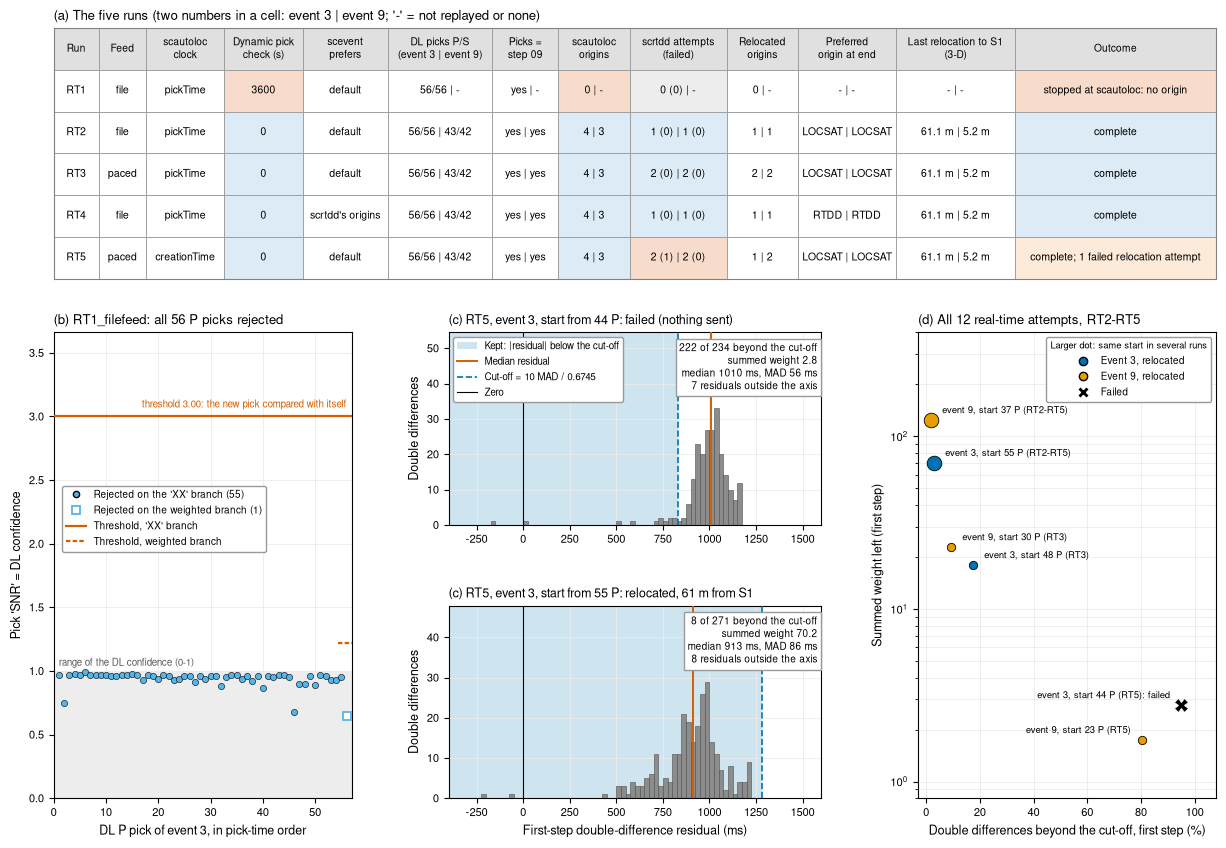

- RT1_filefeed: 55 of 56 P picks failed scautoloc's dynamic pick check on its 'XX' branch (threshold 3.00) and 1 on its weighted branch; the logged 'SNR' values are 0.65-0.99, the DL confidences. With the check switched off (dynamicPickThresholdInterval = 0, RT2 onwards) every run made origins.
- RT5_paced_creationtime: of 12 real-time attempts, 2 started with more than 80 % of their double differences beyond the cut-off; 1 failed. The same failed start relocated offline (`scrtdd --ep`) fails the same way (step 1 at 34.940071 127.796724 -1.8103, step 2 failed); without down-weighting it finishes, at 1.17 km from S1.

In [14]:
# Figure 4: runs table, RT1 panel, RT5 residual panels, all attempts
fig = plt.figure(figsize=(15.0, 10.0))
gs = GridSpec(2, 3, figure=fig, height_ratios=[0.78, 1.45], width_ratios=[1.0, 1.25, 1.0], hspace=0.15, wspace=0.30)
axT = fig.add_subplot(gs[0, :])
cols = list(RUNTAB.columns)
header = {"Run": "Run", "Feed": "Feed", "scautoloc clock": "scautoloc\nclock", "Dynamic pick check (s)": "Dynamic pick\ncheck (s)",
          "scevent prefers": "scevent\nprefers", "DL picks P/S": "DL picks P/S\n(event 3 | event 9)", "Picks = step 09": "Picks =\nstep 09",
          "scautoloc origins": "scautoloc\norigins", "scrtdd attempts (failed)": "scrtdd attempts\n(failed)",
          "Relocated origins": "Relocated\norigins", "Preferred at end": "Preferred\norigin at end",
          "Last relocation to S1": "Last relocation to S1\n(3-D)", "Outcome": "Outcome"}
cell_text = [[str(v).replace("not replayed", "-") for v in r_] for r_ in RUNTAB.to_numpy()]
colors = []
for r_ in RUNTAB.itertuples():
    c = []
    for col in cols:
        v = RUNTAB.loc[r_.Index, col]
        if col == "Outcome":
            c.append(BAD_FC if v.startswith("stopped") else (OK_FC if v == "complete" else "#FCEBD9"))   # light orange: partly failed
        elif col == "scautoloc origins":
            c.append(BAD_FC if v.split(" | ")[0] == "0" else OK_FC)
        elif col == "scrtdd attempts (failed)":
            c.append(NA_FC if v.startswith("0 (0)") else (BAD_FC if any(s.strip().endswith("(1)") for s in v.split("|")) else OK_FC))
        elif col == "Dynamic pick check (s)":
            c.append(BAD_FC if v != "0" else OK_FC)
        else:
            c.append("white")
    colors.append(c)
tb = axT.table(cellText=cell_text, colLabels=[header[c] for c in cols], cellColours=colors, cellLoc="center",
               colLoc="center", loc="upper center", bbox=[0.0, 0.0, 1.0, 1.0])
tb.auto_set_font_size(False)
tb.set_fontsize(7.6)
for (rr_, cc_), cell in tb.get_celld().items():
    cell.set_edgecolor("0.6")
    cell.set_linewidth(0.6)
    if rr_ == 0:
        cell.set_facecolor("0.88")
        cell.set_text_props(fontsize=7.4)
widths = {"Run": 0.038, "Feed": 0.04, "scautoloc clock": 0.066, "Dynamic pick check (s)": 0.066, "scevent prefers": 0.072,
          "DL picks P/S": 0.088, "Picks = step 09": 0.056, "scautoloc origins": 0.06, "scrtdd attempts (failed)": 0.082,
          "Relocated origins": 0.06, "Preferred at end": 0.083, "Last relocation to S1": 0.1, "Outcome": 0.17}
wsum = sum(widths.values())
widths = {c: w / wsum for c, w in widths.items()}
for (rr_, cc_), cell in tb.get_celld().items():
    cell.set_width(widths[cols[cc_]])
axT.set_xticks([])
axT.set_yticks([])
h4.close_box(axT, color="0.5")
axT.set_title("(a) The five runs (two numbers in a cell: event 3 | event 9; '-' = not replayed or none)", loc="left", fontsize=9.5)

# (b) RT1
axb = fig.add_subplot(gs[1, 0])
x = np.arange(1, len(REJ) + 1)
xx = REJ.branch == "XX"
axb.plot(x[xx], REJ.snr[xx], "o", ms=4.5, mfc=COL["P"], mec="k", mew=0.4, zorder=4)
axb.plot(x[~xx], REJ.snr[~xx], "s", ms=5.5, mfc="white", mec=COL["P"], mew=1.3, zorder=4)
thr_xx = REJ.threshold[xx].unique()
axb.axhline(float(thr_xx[0]), color=COL["locsat"], lw=1.6, zorder=3)
for _, r_ in REJ[~xx].iterrows():
    i_ = int(r_.name) + 1
    axb.plot([i_ - 1.6, i_ + 1.6], [r_.threshold, r_.threshold], color=COL["locsat"], lw=1.6, ls=(0, (2, 1)), zorder=3)
axb.axhspan(0, 1, color="0.93", zorder=0)
axb.text(1, 1.02, "range of the DL confidence (0-1)", fontsize=7, va="bottom", ha="left", color="0.35")
axb.text(len(REJ), float(thr_xx[0]) + 0.05, f"threshold {thr_xx[0]:.2f}: the new pick compared with itself", fontsize=7, ha="right",
         va="bottom", color=COL["locsat"])
axb.set_ylim(0, float(thr_xx[0]) * 1.22)
axb.set_xlim(0, len(REJ) + 1)
axb.set_xlabel(f"DL P pick of event {RID[REPLAYED[0]]}, in pick-time order")
axb.set_ylabel("Pick 'SNR' = DL confidence")
axb.set_title(f"(b) {SCAUTOLOC_FAIL_RUN}: all {len(REJ)} P picks rejected", loc="left", fontsize=9.5)
axb.grid(color="0.92", lw=0.6, zorder=0)
h4.close_box(axb)
leg = axb.legend([Line2D([], [], ls="none", marker="o", ms=4.5, mfc=COL["P"], mec="k"),
                  Line2D([], [], ls="none", marker="s", ms=5.5, mfc="white", mec=COL["P"], mew=1.3),
                  Line2D([], [], color=COL["locsat"], lw=1.6), Line2D([], [], color=COL["locsat"], lw=1.6, ls=(0, (2, 1)))],
                 [f"Rejected on the 'XX' branch ({int(xx.sum())})", f"Rejected on the weighted branch ({int((~xx).sum())})",
                  "Threshold, 'XX' branch", "Threshold, weighted branch"], loc="center left", bbox_to_anchor=(0.01, 0.6), fontsize=7.2)
leg.set_zorder(50)

# (c) RT5 residuals: failed start and the next start of the same event
gsc = gs[1, 1].subgridspec(2, 1, hspace=0.42)
axc = [fig.add_subplot(gsc[0, 0]), fig.add_subplot(gsc[1, 0])]
edges = np.arange(RESID_RANGE_MS[0], RESID_RANGE_MS[1] + RESID_BIN_MS, RESID_BIN_MS)
for ax, lab, x_ in ((axc[0], "failed", FAILED), (axc[1], "next", NEXT)):
    r_ = DDR[lab].doubleDifferenceResidual.to_numpy() * 1000
    inside = (r_ >= RESID_RANGE_MS[0]) & (r_ <= RESID_RANGE_MS[1])
    ax.axvspan(-x_.cutoff_ms, x_.cutoff_ms, color=COL["wait"], alpha=0.55, lw=0, zorder=0)
    ax.hist(r_[inside], bins=edges, color="0.55", edgecolor="0.3", lw=0.4, zorder=2)
    ax.axvline(0, color="k", lw=0.8, zorder=3)
    ax.axvline(x_.median_ms, color=COL["locsat"], lw=1.4, zorder=3)
    ax.axvline(x_.cutoff_ms, color=COL["rtdd"], lw=1.2, ls="--", zorder=3)
    ax.set_xlim(*RESID_RANGE_MS)
    ax.set_ylim(0, 1.65 * np.histogram(r_[inside], bins=edges)[0].max())     # free space above the bars for the boxes
    status = "failed (nothing sent)" if not x_.relocated else f"relocated, {x_.d3D_S1_m:.0f} m from S1"
    ax.set_title(f"(c) {x_.run.split('_')[0]}, event {x_.event}, start from {x_.n_P} P: {status}",
                 loc="left", fontsize=9)
    ax.text(0.99, 0.95, f"{x_.beyond} of {x_.n_dd} beyond the cut-off\nsummed weight {x_.sum_weight:.1f}\n"
            f"median {x_.median_ms:.0f} ms, MAD {x_.mad_ms:.0f} ms\n{int((~inside).sum())} residuals outside the axis",
            transform=ax.transAxes, ha="right", va="top", fontsize=7.2, bbox=dict(fc="white", ec="0.6", pad=2.5), zorder=6)
    ax.set_ylabel("Double differences")
    ax.grid(color="0.92", lw=0.6, zorder=0)
    h4.close_box(ax)
axc[1].set_xlabel("First-step double-difference residual (ms)")
leg = axc[0].legend([Patch(color=COL["wait"], alpha=0.55, lw=0), Line2D([], [], color=COL["locsat"], lw=1.4),
                     Line2D([], [], color=COL["rtdd"], lw=1.2, ls="--"), Line2D([], [], color="k", lw=0.8)],
                    ["Kept: |residual| below the cut-off", "Median residual", "Cut-off = 10 MAD / 0.6745", "Zero"],
                    loc="upper left", fontsize=7.0)
leg.set_zorder(50)

# (d) every attempt
axd = fig.add_subplot(gs[1, 2])
g = WT.groupby(["event", "n_P", "median_ms", "mad_ms", "beyond_pct", "sum_weight", "relocated"], as_index=False).agg(
    runs=("run", lambda s: ", ".join(sorted({x.split("_")[0] for x in s}))), n=("run", "size"), d3D_S1_m=("d3D_S1_m", "first"))
for _, r_ in g.iterrows():
    c = COL["rtdd"] if r_.event == RID[REPLAYED[0]] else COL["S"]
    if r_.relocated:
        axd.plot(r_.beyond_pct, r_.sum_weight, "o", ms=6 + 1.5 * (r_.n - 1), mfc=c, mec="k", mew=0.6, zorder=4)
    else:
        axd.plot(r_.beyond_pct, r_.sum_weight, "X", ms=10, mfc=COL["fail"], mec="white", mew=0.6, zorder=5)
    rl = r_.runs.split(", ")
    runs_txt = f"{rl[0]}-{rl[-1]}" if len(rl) > 2 and [int(x[2:]) for x in rl] == list(range(int(rl[0][2:]), int(rl[-1][2:]) + 1)) else r_.runs
    txt = f"event {r_.event}, start {r_.n_P} P ({runs_txt})" + ("" if r_.relocated else ": failed")
    right = r_.beyond_pct > 60
    axd.annotate(txt, (r_.beyond_pct, r_.sum_weight), xytext=(-8 if right else 8, 5), textcoords="offset points", fontsize=6.8,
                 ha="right" if right else "left", zorder=6)
axd.set_yscale("log")
axd.set_xlim(-3, 108)
axd.set_ylim(0.8, 400)
axd.set_xlabel("Double differences beyond the cut-off, first step (%)")
axd.set_ylabel("Summed weight left (first step)")
axd.set_title(f"(d) All {len(WT)} real-time attempts, RT2-RT5", loc="left", fontsize=9.5)
axd.grid(color="0.92", lw=0.6, zorder=0, which="both")
h4.close_box(axd)
leg = axd.legend([Line2D([], [], ls="none", marker="o", ms=6, mfc=COL["rtdd"], mec="k"),
                  Line2D([], [], ls="none", marker="o", ms=6, mfc=COL["S"], mec="k"),
                  Line2D([], [], ls="none", marker="X", ms=9, mfc=COL["fail"], mec="white")],
                 [f"Event {RID[REPLAYED[0]]}, relocated", f"Event {RID[REPLAYED[1]]}, relocated", "Failed"],
                 loc="upper right", fontsize=7.2, title="Larger dot: same start in several runs", title_fontsize=6.8)
leg.set_zorder(50)
FIGS["4"] = h4.save_fig(fig, FIG_DIR, "04_4_runs_and_failures", dpi=DPI)
plt.show()
off_f = OFFFAIL.set_index("variant")
display(Markdown(
    f"- {SCAUTOLOC_FAIL_RUN}: {int(xx.sum())} of {len(REJ)} P picks failed scautoloc's dynamic pick check on its 'XX' branch "
    f"(threshold {thr_xx[0]:.2f}) and {int((~xx).sum())} on its weighted branch; the logged 'SNR' values are "
    f"{REJ.snr.min():.2f}-{REJ.snr.max():.2f}, the DL confidences. With the check switched off "
    f"(dynamicPickThresholdInterval = 0, RT2 onwards) every run made origins.\n"
    f"- {RELOC_FAIL_RUN}: of {len(WT)} real-time attempts, {int((WT.beyond_pct > 80).sum())} started with more than 80 % of their "
    f"double differences beyond the cut-off; {int((~WT.relocated).sum())} failed. The same failed start relocated offline (`scrtdd --ep`) "
    f"fails the same way (step 1 at {off_f.loc['P', 'step1_location']}, step 2 {'failed' if not off_f.loc['P', 'step2_ok'] else 'ok'}); "
    f"without down-weighting it finishes, at {np.linalg.norm(RA.enu([off_f.loc['P_nodw', 'reloc_lat']], [off_f.loc['P_nodw', 'reloc_lon']], [off_f.loc['P_nodw', 'reloc_depth_km']])[0] - S1.loc[RID[FAILED.kma_id], ['E', 'N', 'U']].to_numpy(float)) / 1000:.2f} km from S1."))

## 6. Figure 5: P only (real time) against P + S (offline)

**What the figure shows.** scautoloc associates only P picks, so every origin scrtdd receives has P arrivals
only, although scautopick made S picks too and they are in the database. After the runs, `rt_offline_check.py`
took the scautoloc origin that scrtdd relocated in RT2_filefeed and relocated it offline with the same profile and
catalog (`scrtdd --ep`), once with its P arrivals only and once with the DL S picks added. Left: the 3-D distance
of each result from S1, with step 08's offline single-event result SEa (PhaseNet+ P and S picks) for comparison.
Middle and right: the positions in map view and depth section, zoomed so that each event's largest offset fits
(the scale differs between the two events). The offline P-only result lies exactly on the real-time one.

In [15]:
# Figure 5 data: real-time P-only relocation, offline P and P+S, SEa, S1
P5 = {}
pos2 = R[MAIN_RUN]["positions_vs_reference"]
for k in REPLAYED:
    rid = RID[k]
    oc = OFFCHK[OFFCHK.kma_id == k].set_index("variant")
    xyz = {v: RA.enu([oc.loc[v, "reloc_lat"]], [oc.loc[v, "reloc_lon"]], [oc.loc[v, "reloc_depth_km"]])[0] for v in ("P", "PS")}
    rt = P3[k]["rtdd"]

    def d_file(sol, vs):
        q = pos2[(pos2.kma_id == k) & (pos2.solution == sol) & (pos2.versus == vs) & (pos2.kind == "absolute")]
        return float(q.d3D_m.iloc[0])

    s1 = S1.loc[rid, ["E", "N", "U"]].to_numpy(float)
    sea = SEA.loc[rid, ["E", "N", "U"]].to_numpy(float)
    P5[k] = dict(s1=s1, sea=sea, rt=rt[["E", "N", "U"]].to_numpy(float), P=xyz["P"], PS=xyz["PS"],
                 n=dict(P=(int(oc.loc["P", "reloc_n_arr_P"]), int(oc.loc["P", "reloc_n_arr_S"])),
                        PS=(int(oc.loc["PS", "reloc_n_arr_P"]), int(oc.loc["PS", "reloc_n_arr_S"])), S_added=int(oc.loc["PS", "n_S_added"])),
                 d=dict(rt=d_file("RTDD_1", "S1"), P=d_file("offline_ep_P", "S1"), PS=d_file("offline_ep_PS", "S1"),
                        sea=float(CTX[(CTX.rtdd_id == rid) & (CTX.versus == "SEa")].d3D_m.iloc[0]),
                        P_rt=d_file("offline_ep_P", "realtime_RTDD"), PS_rt=d_file("offline_ep_PS", "realtime_RTDD"),
                        PS_sea=d_file("offline_ep_PS", "SEa"), rt_sea=d_file("RTDD_1", "SEa")),
                 cc=dict(P=(int(oc.loc["PS", "cc_P_above"]), int(oc.loc["PS", "cc_P_attempted"])),
                         S=(int(oc.loc["PS", "cc_S_above"]), int(oc.loc["PS", "cc_S_attempted"]))))
    # checks: distances recomputed here
    assert abs(np.linalg.norm(P5[k]["PS"] - s1) - P5[k]["d"]["PS"]) < 0.002
    assert abs(np.linalg.norm(P5[k]["P"] - P5[k]["rt"])) < 0.002
    assert abs(np.linalg.norm(sea - s1) - P5[k]["d"]["sea"]) < 0.006     # the context file rounds to 1 cm

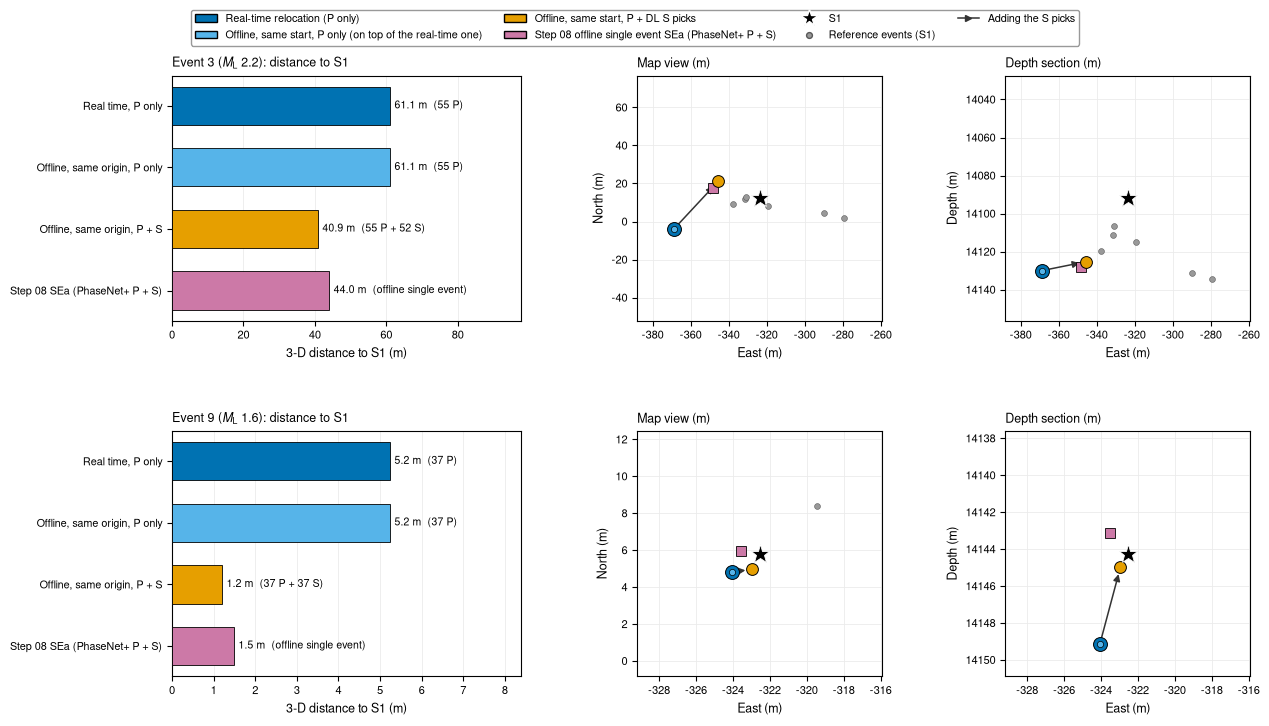

,Event,Real time (P only) to S1 (m),Offline P only to the real-time origin (m),Offline P + S to S1 (m),Offline P + S to SEa (m),SEa to S1 (m),S picks added / kept,S cross-correlations >= threshold
0,3,61.05,0.0,40.87,5.42,44.03,55 / 52,273 of 315
1,9,5.24,0.0,1.21,2.18,1.49,38 / 37,242 of 258


In [16]:
# Figure 5: distances and positions, P only against P + S
nev = len(REPLAYED)
fig = plt.figure(figsize=(14.0, 3.9 * nev))
gs = GridSpec(nev, 3, figure=fig, width_ratios=[1.35, 1.0, 1.0], wspace=0.38, hspace=0.45)
AX5 = []
BARS = [("rt", "Real time, P only", COL["rtdd"]), ("P", "Offline, same origin, P only", COL["rtdd_early"]),
        ("PS", "Offline, same origin, P + S", COL["ps"]), ("sea", "Step 08 SEa (PhaseNet+ P + S)", COL["sea"])]
for i, k in enumerate(REPLAYED):
    D = P5[k]
    ab = fig.add_subplot(gs[i, 0])
    y = np.arange(len(BARS))[::-1]
    vals = [D["d"][key] for key, _, _ in BARS]
    ab.barh(y, vals, color=[c for _, _, c in BARS], edgecolor="k", lw=0.6, height=0.62, zorder=3)
    for yy, v, (key, lab, _) in zip(y, vals, BARS):
        extra = {"rt": f"{D['n']['P'][0]} P", "P": f"{D['n']['P'][0]} P", "PS": f"{D['n']['PS'][0]} P + {D['n']['PS'][1]} S",
                 "sea": "offline single event"}[key]
        ab.text(v + max(vals) * 0.02, yy, f"{v:.1f} m  ({extra})", va="center", ha="left", fontsize=7.6, zorder=4)
    ab.set_yticks(y)
    ab.set_yticklabels([lab for _, lab, _ in BARS], fontsize=7.8)
    ab.set_xlim(0, max(vals) * 1.6)
    ab.set_xlabel("3-D distance to S1 (m)")
    ab.set_title(f"{evlabel(k)}: distance to S1", loc="left", fontsize=9)
    ab.grid(axis="x", color="0.92", lw=0.6, zorder=0)
    h4.close_box(ab)
    half = max(FIG5_MIN_HALF_M, FIG5_ZOOM_FACTOR * max(np.linalg.norm((D[x] - D["s1"])[:2]) if j == 0 else abs((D[x] - D["s1"])).max()
                                                       for x in ("rt", "PS", "sea") for j in (0, 1)))
    for j, (ax, mode) in enumerate(((fig.add_subplot(gs[i, 1]), "map"), (fig.add_subplot(gs[i, 2]), "depth"))):
        f = (lambda v: (v[0], v[1])) if mode == "map" else (lambda v: (v[0], -v[2]))
        ctr = f(D["s1"])
        refs = S1.loc[REF_IDS, ["E", "N", "U"]].to_numpy(float)
        for rv in refs:
            ax.plot(*f(rv), "o", ms=4.2, mfc=COL["ref"], mec="0.35", mew=0.4, zorder=2)
        ax.plot(*f(D["s1"]), "*", ms=14, mfc=COL["s1"], mec="white", mew=0.6, zorder=5)
        ax.plot(*f(D["sea"]), "s", ms=7, mfc=COL["sea"], mec="k", mew=0.6, zorder=4)
        ax.plot(*f(D["rt"]), "o", ms=10, mfc=COL["rtdd"], mec="k", mew=0.7, zorder=4)
        ax.plot(*f(D["P"]), "o", ms=4.5, mfc=COL["rtdd_early"], mec="k", mew=0.5, zorder=5)
        ax.plot(*f(D["PS"]), "o", ms=8.5, mfc=COL["ps"], mec="k", mew=0.7, zorder=4)
        ax.annotate("", xy=f(D["PS"]), xytext=f(D["P"]), arrowprops=dict(arrowstyle="-|>", color="0.2", lw=1.1, shrinkA=5, shrinkB=5,
                                                                           mutation_scale=10), zorder=3)
        ax.set_xlim(ctr[0] - half, ctr[0] + half)
        if mode == "map":
            ax.set_ylim(ctr[1] - half, ctr[1] + half)
            ax.set_ylabel("North (m)")
            ax.set_title("Map view (m)", loc="left", fontsize=9)
        else:
            ax.set_ylim(ctr[1] + half, ctr[1] - half)
            ax.set_ylabel("Depth (m)")
            ax.set_title("Depth section (m)", loc="left", fontsize=9)
        ax.set_aspect("equal", adjustable="box")
        ax.set_xlabel("East (m)")
        ax.grid(color="0.92", lw=0.6, zorder=0)
        h4.close_box(ax)
        AX5.append(ax)
    AX5.append(ab)
handles = [Patch(fc=COL["rtdd"], ec="k"), Patch(fc=COL["rtdd_early"], ec="k"), Patch(fc=COL["ps"], ec="k"), Patch(fc=COL["sea"], ec="k"),
           Line2D([], [], ls="none", marker="*", ms=13, mfc=COL["s1"], mec="white"),
           Line2D([], [], ls="none", marker="o", ms=4.2, mfc=COL["ref"], mec="0.35"), Line2D([], [], color="0.2", lw=1.1, marker=">", ms=5)]
labels = ["Real-time relocation (P only)", "Offline, same start, P only (on top of the real-time one)", "Offline, same start, P + DL S picks",
          "Step 08 offline single event SEa (PhaseNet+ P + S)", "S1", "Reference events (S1)", "Adding the S picks"]
h4.legend_above(fig, AX5, handles, labels, ncol=4, fontsize=7.8)
FIGS["5"] = h4.save_fig(fig, FIG_DIR, "04_5_p_only_vs_p_plus_s", dpi=DPI)
plt.show()
rows = []
for k in REPLAYED:
    D = P5[k]
    rows.append({"Event": RID[k], "Real time (P only) to S1 (m)": D["d"]["rt"], "Offline P only to the real-time origin (m)": D["d"]["P_rt"],
                 "Offline P + S to S1 (m)": D["d"]["PS"], "Offline P + S to SEa (m)": D["d"]["PS_sea"], "SEa to S1 (m)": D["d"]["sea"],
                 "S picks added / kept": f"{D['n']['S_added']} / {D['n']['PS'][1]}",
                 "S cross-correlations >= threshold": f"{D['cc']['S'][0]} of {D['cc']['S'][1]}"})
PSTAB = pd.DataFrame(rows)
display(PSTAB.round(2))

## 7. Comprehensive summary

### 7.1 Key numbers

Every value below is read from the run files or computed in the sections above; the table is built in code.

In [17]:
# 7.1 the key numbers in one table
def lat(run, k, key, second=False):
    dl = R[run]["delays"].set_index("kma_id").loc[k]
    a = dl.get(f"latency_{key}_after_origin_time_s")
    b = dl.get(f"latency_{key}_after_S1_origin_time_msrtsimul_clock_s")
    return "-" if (a is None or pd.isna(a)) else f"{float(a):.1f} [{float(b):.1f}]"


rows = {}
for k in REPLAYED:
    kp = R[MAIN_RUN]["positions_vs_reference"]
    st = kp[(kp.kma_id == k) & (kp.solution == "scautoloc_final") & (kp.versus == "S1") & (kp.kind == "absolute")].iloc[0]
    pv = R[MAIN_RUN]["picks_vs_offline"].set_index("kma_id").loc[k]
    col = evlabel(k).replace(ML, "ML")
    rows[col] = {
        "DL picks in the database, P / S (main run)": f"{int(pv.n_rt_DL3C)} / {int(pv.n_rt_SDL3C)}",
        "Picks identical to step 09's offline picks (all runs that replayed it)":
            "yes" if all(COMP[run]["events"][k]["picks_identical_to_step09"] for run in RUNS if any(x["event"] == k for x in R[run]["replays"])) else "no",
        "LOCSAT start vs S1: horizontal / vertical (+ = too shallow) / origin time":
            f"{st.dH_m:.0f} m / {st.dU_m:+.0f} m / {st.dT_ms / 1000:+.2f} s",
        "Real-time relocation vs S1, 3-D (P only)": f"{P5[k]['d']['rt']:.1f} m",
        "Offline, same start, P + S vs S1, 3-D": f"{P5[k]['d']['PS']:.1f} m",
        "Real-time relocation vs HypoDD dt.cc, catalog-relative": f"{P3[k]['d_hdd_rel']:.1f} m",
        **{f"{run.split('_')[0]}: first DL pick / first origin / event (s)":
           f"{lat(run, k, 'first_DL_pick_created')} / {lat(run, k, 'first_origin_created')} / {lat(run, k, 'event_created')}" for run in PACED_RUNS},
        **{f"{run.split('_')[0]}: first / last relocated origin (s)":
           f"{lat(run, k, 'RTDD_1_created')} / {lat(run, k, 'RTDD_' + str(int(R[run]['delays'].set_index('kma_id').loc[k].n_RTDD_origins)) + '_created')}"
           for run in PACED_RUNS},
        "Relocation attempts RT2-RT5 (failed)": f"{int((WT.kma_id == k).sum())} ({int(((WT.kma_id == k) & ~WT.relocated).sum())})",
    }
SUMTAB = pd.DataFrame(rows)
display(Markdown("Latencies: seconds after the final LOCSAT origin time [after S1's origin time on msrtsimul's clock]."))
display(SUMTAB)

Latencies: seconds after the final LOCSAT origin time [after S1's origin time on msrtsimul's clock].

,Event 3 (ML 2.2),Event 9 (ML 1.6)
"DL picks in the database, P / S (main run)",56 / 56,43 / 42
Picks identical to step 09's offline picks (all runs that replayed it),yes,yes
LOCSAT start vs S1: horizontal / vertical (+ = too shallow) / origin time,349 m / +2709 m / -0.83 s,510 m / +3881 m / -0.69 s
"Real-time relocation vs S1, 3-D (P only)",61.1 m,5.2 m
"Offline, same start, P + S vs S1, 3-D",40.9 m,1.2 m
"Real-time relocation vs HypoDD dt.cc, catalog-relative",54.6 m,8.8 m
RT3: first DL pick / first origin / event (s),15.1 [13.7] / 38.3 [37.0] / 38.6 [37.3],13.3 [12.1] / 40.4 [39.2] / 40.7 [39.5]
RT5: first DL pick / first origin / event (s),15.1 [13.7] / 38.4 [37.1] / 38.7 [37.4],13.3 [12.1] / 40.5 [39.3] / 40.8 [39.6]
RT3: first / last relocated origin (s),62.8 [61.5] / 229.2 [227.9],60.5 [59.3] / 280.6 [279.4]
RT5: first / last relocated origin (s),232.6 [231.3] / 232.6 [231.3],58.8 [57.6] / 73.1 [71.9]


### 7.2 Take-home messages, caveats and inconsistencies

The text below is generated from the values above.

In [18]:
# 7.2 take-home messages, caveats, inconsistencies found (all numbers formatted from variables)
k3, k9 = REPLAYED
d3 = {r_: R[r_]["delays"].set_index("kma_id") for r_ in PACED_RUNS}
r3, r5 = PACED_RUNS
dmin = lambda col: min(float(d3[r_].loc[k, col]) for r_ in PACED_RUNS for k in REPLAYED)
dmax = lambda col: max(float(d3[r_].loc[k, col]) for r_ in PACED_RUNS for k in REPLAYED)
pmed = [float(d3[r_].loc[k, "DL3C_latency_after_pick_time_median_s"]) for r_ in PACED_RUNS for k in REPLAYED]
smed = [float(d3[r_].loc[k, "SDL3C_latency_after_pick_time_median_s"]) for r_ in PACED_RUNS for k in REPLAYED]
mbm = list(MB_MED.values())
waits = pd.concat([TL[key]["att"].assign(wait=lambda a: a.start_s - a.input_created_s, comp=lambda a: a.end_s - a.start_s) for key in TL])
P_WIN = R[MAIN_RUN]["settings"]["plugin_resolved"]["picker.DL3C"]["resolved"]


def start_vs_s1(k, col):
    kp = R[MAIN_RUN]["positions_vs_reference"]
    q = kp[(kp.kma_id == k) & (kp.solution == "scautoloc_final") & (kp.versus == "S1") & (kp.kind == "absolute")]
    return float(q[col].iloc[0])


take = [
    f"- **The real-time chain runs on Server A, localhost only.** After one scautoloc setting (its dynamic pick check off), every run "
    f"from RT2 on went from the waveform file to a relocated origin in the database for both earthquakes. The DL picks made in "
    f"messaging mode are exactly step 09's offline picks. The only listening socket in all {len(NET)} runs was scmaster's {FLOW['bind']}.",
    f"- **How fast (paced feed).** In {r3.split('_')[0]} the first relocated origin came "
    + " and ".join(f"{float(d3[r3].loc[k, 'latency_RTDD_1_created_after_origin_time_s']):.1f} s (event {RID[k]})" for k in REPLAYED)
    + f" after the final LOCSAT origin time; the first origin and the event came after "
    f"{dmin('latency_first_origin_created_after_origin_time_s'):.1f}-{dmax('latency_event_created_after_origin_time_s'):.1f} s in both paced runs. "
    f"In {r5.split('_')[0]} event {RID[k9]} was relocated after {float(d3[r5].loc[k9, 'latency_RTDD_1_created_after_origin_time_s']):.1f} s, "
    f"but event {RID[k3]} only after {float(d3[r5].loc[k3, 'latency_RTDD_1_created_after_origin_time_s']):.1f} s, because its first attempt failed "
    f"(Figure 4). The time goes into three waits: the DL picker reports a P pick a median {min(pmed):.1f}-{max(pmed):.1f} s after the wave "
    f"arrives (its analysis window ends {P_WIN['minLatency_s']:.0f} s after the detector trigger) and an S pick {min(smed):.1f}-{max(smed):.1f} s after; "
    f"scautoloc then waits for each P pick's mb amplitude, a median {min(mbm):.1f}-{max(mbm):.1f} s more; scrtdd waits "
    f"{waits.wait.min():.0f}-{waits.wait.max():.0f} s (delayTime {FLOW['delay']} s) and computes {waits.comp.min():.0f}-{waits.comp.max():.0f} s "
    "(scrtdd's log, 1-s resolution).",
    f"- **How accurate.** LOCSAT (global model {FLOW['loc_profile']}) starts "
    + " and ".join(f"{abs(start_vs_s1(k, 'dU_m')) / 1000:.1f} km" for k in REPLAYED)
    + f" too shallow; scrtdd moves the events by {P3[k3]['d_start_rtdd'] / 1000:.1f} and {P3[k9]['d_start_rtdd'] / 1000:.1f} km to "
    f"{P5[k3]['d']['rt']:.1f} m (event {RID[k3]}) and {P5[k9]['d']['rt']:.1f} m (event {RID[k9]}) from S1. The real-time result is the "
    f"offline result of the same start ({P5[k3]['d']['P_rt']:.2f} m apart).",
    f"- **What holds it back.** (1) S picks never reach scrtdd, because scautoloc associates only P: adding the DL S picks offline brings "
    f"the events to {P5[k3]['d']['PS']:.1f} m and {P5[k9]['d']['PS']:.1f} m from S1. (2) The waits above; the picker's and the mb "
    f"amplitude's dominate. (3) The LOCSAT start: its origin time is about a second off, which made one of {len(WT)} attempts fail "
    f"through scrtdd's residual down-weighting measured from zero. (4) With scevent's default priorities the relocated origin "
    f"rarely stays preferred (only RT4, set to prefer it, ended with it preferred).",
]
cav = [
    "- **Two events only.** They show that the chain works; they are not statistics. Event 3 is the least consistent event of the "
    "cluster in every earlier step.",
    f"- **The reference catalog is S1, and S1 was computed with events {RID[k3]} and {RID[k9]} included.** The catalog itself leaves "
    "them out, but its positions come from an inversion that used them, so the agreement with S1 is not a fully independent test "
    "(a leave-two-out catalog was not built). HypoDD's frame differs from S1's; compare with HypoDD only catalog-relative.",
    f"- **Playback timing.** The file feed shows processing time, not latency. msrtsimul releases each record 0-1 s early "
    f"(the two latency references differ by "
    + " and ".join(f"{float(d3[r3].loc[k, 'latency_first_origin_created_after_origin_time_s'] - d3[r3].loc[k, 'latency_first_origin_created_after_S1_origin_time_msrtsimul_clock_s']):.2f} s"
                   for k in REPLAYED)
    + "). scautoloc's playback clock holds updates until the next pick arrives (the late updates at "
    + ", ".join(f"{float(d3[r_].loc[k, 'latency_final_scautoloc_origin_created_after_origin_time_s']):.0f} s" for r_ in PACED_RUNS for k in REPLAYED
                if float(d3[r_].loc[k, 'latency_final_scautoloc_origin_created_after_origin_time_s']) > TIMELINE_EARLY_S[1])
    + "); live operation would not wait like this. scrtdd's log times have 1-s resolution, so the wait and computing bars of "
    "Figure 2 are good to 1 s.",
    f"- **Event {RID[k9]}'s 'first DL pick' is a pick timed before the earthquake** (Figure 2 table), so that one latency "
    "is not a property of the earthquake.",
]
incons = []
q = PICKTAB[PICKTAB["its pick time after the origin (s)"] < 0]
for ev_, g_ in q.groupby("Event"):
    r_ = g_.iloc[0]
    incons.append(f"- **'First DL pick' of event {ev_}** (`delays.csv` of {', '.join(g_.Run)}; `summary_all_runs.json`; note 10's "
                  f"'first DL P pick'): the {r_['its creation (s)']:.1f} s value belongs to the pick {r_['First DL pick: station, method']}, "
                  f"timed {abs(r_['its pick time after the origin (s)']):.1f} s BEFORE the origin time, so it is not a pick of the earthquake. "
                  f"The first pick timed after the origin was created at "
                  + " / ".join(f"{x:.1f}" for x in g_["First pick timed after the origin: creation (s)"]) + " s. The numbers in the "
                  "files are right as defined (earliest pick in the replay window); only their reading as the earthquake's first pick is not.")
incons.append(f"- mb amplitude delay (note 10, section 4.5: 'a median 14.0 s after the pick'; no script writes it): consistent. From the "
              f"database copies, per run and event: "
              + "; ".join(f"{run_.split('_')[0]} event {ev_} {v_:.2f} s" for (run_, ev_), v_ in MB_MED.items())
              + "; pooled per run: " + ", ".join(f"{r_.split('_')[0]} {v_:.2f} s" for r_, v_ in MB_POOLED.items()) + ".")
incons.append("- `summary_all_runs.json` rounds distances to 1 cm (e.g. event 3's relocation as 61.05 m); formatting that to one "
              "decimal gives 61.0 m, while the 1-mm value in `positions_vs_reference.csv` gives the 61.1 m of note 10. This notebook "
              "takes distances from the per-run position tables.")
checks = [f"database copies = db_dump read-backs in all {len(DBCHECK)} runs",
          f"{len(CHK)} origin-to-S1 distances recomputed (largest difference {CHK.diff_m.abs().max():.4f} m)",
          f"reference catalogs = S1 positions (largest offset {CATCHK.largest_offset_from_S1_m.max():.4f} m), replayed events absent",
          f"{len(DIFF)} latency values in the combined files = per-run tables (largest difference {DIFF['diff'].max():.4f} s)",
          "Figure 2's own latencies = delays.csv (asserted per panel)",
          "first-step residual statistics = scrtdd_step1_weighting.csv"]
display(Markdown("**Take-home messages**\n\n" + "\n".join(take)))
display(Markdown("**Caveats**\n\n" + "\n".join(cav)))
display(Markdown("**Inconsistencies and subtleties found between files and note 10**\n\n" + "\n".join(incons)
                 + "\n\n**Checks that passed:** " + "; ".join(checks) + "."))
print("figures written:")
for k_, (png, pdf) in FIGS.items():
    print(f"  Figure {k_}: {png}  |  {pdf}")

**Take-home messages**

- **The real-time chain runs on Server A, localhost only.** After one scautoloc setting (its dynamic pick check off), every run from RT2 on went from the waveform file to a relocated origin in the database for both earthquakes. The DL picks made in messaging mode are exactly step 09's offline picks. The only listening socket in all 5 runs was scmaster's 127.0.0.1:28180.
- **How fast (paced feed).** In RT3 the first relocated origin came 62.8 s (event 3) and 60.5 s (event 9) after the final LOCSAT origin time; the first origin and the event came after 38.3-40.8 s in both paced runs. In RT5 event 9 was relocated after 58.8 s, but event 3 only after 232.6 s, because its first attempt failed (Figure 4). The time goes into three waits: the DL picker reports a P pick a median 17.0-18.1 s after the wave arrives (its analysis window ends 15 s after the detector trigger) and an S pick 24.4-26.1 s after; scautoloc then waits for each P pick's mb amplitude, a median 14.0-14.3 s more; scrtdd waits 10-12 s (delayTime 10 s) and computes 1-5 s (scrtdd's log, 1-s resolution).
- **How accurate.** LOCSAT (global model iasp91) starts 2.7 km and 3.9 km too shallow; scrtdd moves the events by 2.8 and 3.9 km to 61.1 m (event 3) and 5.2 m (event 9) from S1. The real-time result is the offline result of the same start (0.00 m apart).
- **What holds it back.** (1) S picks never reach scrtdd, because scautoloc associates only P: adding the DL S picks offline brings the events to 40.9 m and 1.2 m from S1. (2) The waits above; the picker's and the mb amplitude's dominate. (3) The LOCSAT start: its origin time is about a second off, which made one of 12 attempts fail through scrtdd's residual down-weighting measured from zero. (4) With scevent's default priorities the relocated origin rarely stays preferred (only RT4, set to prefer it, ended with it preferred).

**Caveats**

- **Two events only.** They show that the chain works; they are not statistics. Event 3 is the least consistent event of the cluster in every earlier step.
- **The reference catalog is S1, and S1 was computed with events 3 and 9 included.** The catalog itself leaves them out, but its positions come from an inversion that used them, so the agreement with S1 is not a fully independent test (a leave-two-out catalog was not built). HypoDD's frame differs from S1's; compare with HypoDD only catalog-relative.
- **Playback timing.** The file feed shows processing time, not latency. msrtsimul releases each record 0-1 s early (the two latency references differ by 1.33 s and 1.19 s). scautoloc's playback clock holds updates until the next pick arrives (the late updates at 217 s, 269 s, 216 s); live operation would not wait like this. scrtdd's log times have 1-s resolution, so the wait and computing bars of Figure 2 are good to 1 s.
- **Event 9's 'first DL pick' is a pick timed before the earthquake** (Figure 2 table), so that one latency is not a property of the earthquake.

**Inconsistencies and subtleties found between files and note 10**

- **'First DL pick' of event 9** (`delays.csv` of RT3_paced, RT5_paced_creationtime; `summary_all_runs.json`; note 10's 'first DL P pick'): the 13.3 s value belongs to the pick HCNA DL3C, timed 20.1 s BEFORE the origin time, so it is not a pick of the earthquake. The first pick timed after the origin was created at 15.3 / 15.3 s. The numbers in the files are right as defined (earliest pick in the replay window); only their reading as the earthquake's first pick is not.
- mb amplitude delay (note 10, section 4.5: 'a median 14.0 s after the pick'; no script writes it): consistent. From the database copies, per run and event: RT3 event 3 14.04 s; RT3 event 9 14.01 s; RT5 event 3 14.29 s; RT5 event 9 14.01 s; pooled per run: RT3 14.01 s, RT5 14.02 s.
- `summary_all_runs.json` rounds distances to 1 cm (e.g. event 3's relocation as 61.05 m); formatting that to one decimal gives 61.0 m, while the 1-mm value in `positions_vs_reference.csv` gives the 61.1 m of note 10. This notebook takes distances from the per-run position tables.

**Checks that passed:** database copies = db_dump read-backs in all 5 runs; 27 origin-to-S1 distances recomputed (largest difference 0.0004 m); reference catalogs = S1 positions (largest offset 0.0000 m), replayed events absent; 140 latency values in the combined files = per-run tables (largest difference 0.0000 s); Figure 2's own latencies = delays.csv (asserted per panel); first-step residual statistics = scrtdd_step1_weighting.csv.

figures written:
  Figure 1: /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/04_1_data_flow.png  |  /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/04_1_data_flow.pdf
  Figure 2: /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/04_2_latency_timeline.png  |  /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/04_2_latency_timeline.pdf
  Figure 3: /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/04_3_positions.png  |  /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/04_3_positions.pdf
  Figure 4: /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/04_4_runs_and_failures.png  |  /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/04_4_runs_and_failures.pdf
  Figure 5: /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/04_5_p_only_vs_p_plus_s.png  |  /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/04_5_p_only_vs_p_plus_s.pdf


### 7.3 How to reproduce

This notebook (nothing is replayed; CPU only; no SeisComP program is started):

```bash
cd /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks
source /home/msseo/miniforge3/etc/profile.d/conda.sh && conda activate pyrtdd
python build_04_gwangyang_realtime.py        # writes 04_gwangyang_realtime.ipynb (and compiles every code cell)
rm -f figures/04_*.png figures/04_*.pdf      # remove old figures
jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=pyrtdd \
    --ExecutePreprocessor.timeout=1800 04_gwangyang_realtime.ipynb
```

The runs themselves (SeisComP environment; each script is a dry run unless `--apply` is given; full commands in
note 10, section 7):

```bash
cd /home/msseo/works/74.SeisComP_rtDD_DLpicker
source install/env_seiscomp.sh
S=runs/gwangyang/realtime/scripts
python $S/rt_chain.py prepare --run <run> --apply      # options: --autoloc-timing creationTime (RT5), --prefer-rtdd (RT4)
python $S/rt_chain.py start   --run <run> --apply      # scmaster (127.0.0.1:28180), scevent, scautoloc, scrtdd
python $S/rt_chain.py replay  --run <run> --event 20210827220322 --apply   # --feed paced for msrtsimul
python $S/rt_chain.py replay  --run <run> --event 20260202194119 --apply
python $S/rt_chain.py stop    --run <run> --apply
python $S/rt_chain.py dump    --run <run> --apply
python $S/rt_options.py       --run <run> --apply
python $S/rt_offline_check.py --run <run> --apply      # scrtdd --ep on the same origin: P only and P+S
python -I $S/rt_analyze.py --runs RT1_filefeed,RT2_filefeed,RT3_paced,RT4_filefeed_prefer_rtdd,RT5_paced_creationtime --apply   # env pyrtdd
```

- Inputs read here: `runs/gwangyang/realtime/<run>/` (results, options, logs, network, `db/seiscomp.sqlite` via
  copies, `reference_catalog/`, `work/scrtdd/singleevent_*/step1/initial-double-difference.csv`),
  `runs/gwangyang/realtime/comparison/`, the S1, HypoDD dt.cc and SEa tables named by `rt_analyze.py`, and
  `data/gwangyang_11ev/reference_tables/event_id_map.csv`.
- Helper code: `notebooks/lib/nb04_helpers.py` (file, database-copy and plotting helpers); positions and times use
  `rt_analyze.py`'s own `enu()`, `t_sql()`, `t_log()`, `load_solution()` and `load_se()`, and the database is read
  with `rt_chain.py`'s own SQL queries.
- Outputs: figures `notebooks/figures/04_*.png` (200 dpi) and `.pdf`; nothing else is written (the temporary
  database copies are deleted after reading).

In [19]:
# run time of this execution
print(f"run time {(_time.time() - T_START) / 60.0:.1f} min")

run time 0.2 min
